# Лабораторна робота № 5–6
## Нейронна мережа і регуляризація

**Мета:** реалізувати повнозв'язну нейронну мережу (MLP) **з нуля на NumPy** (прямий прохід, backpropagation, SGD, збереження ваг), а потім дослідити, як різні методи регуляризації (**L1, L2, Dropout, weight clipping, gradient clipping** та їх комбінація) впливають на:
- розподіл ваг і **розрідженість** (частку майже нульових ваг);
- кількість **мертвих нейронів** ReLU;
- **якість** класифікації на валідаційній вибірці.

**Датасет:** FashionMNIST — чорно-білі зображення одягу 28×28 пікселів, 10 класів.

**План:**
- **Блок 1.** Дані → архітектура → прямий прохід → backpropagation → перевірка градієнтів чисельно → цикл навчання та графіки → збереження й відновлення ваг.
- **Блок 2.** Базовий експеримент → мертві нейрони → L2 → L1 → Dropout → weight clipping → gradient clipping → L2 + Dropout → порівняльна таблиця, гістограми, діаграма «мертві нейрони ↔ точність» → аналіз і висновки.

## Підготовка: імпорт бібліотек і SEED

Використовуємо лише **NumPy** (усі обчислення мережі), **Matplotlib** (графіки) і **pandas** (таблиці). Жодних PyTorch/TensorFlow чи автоматичного диференціювання: усі похідні рахуємо вручну.

`SEED = 42` фіксує випадковість: початкові ваги, перемішування даних, маски Dropout. Важливо, що **всі експерименти починаються з однакових початкових ваг і бачать дані в однаковому порядку**, тож різниця між ними виникає лише через метод регуляризації.

In [1]:
import os, gzip, json, time, urllib.request, warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
np.random.seed(SEED)
plt.rcParams['figure.dpi'] = 100
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

import matplotlib, platform
print('Python', platform.python_version(), '| NumPy', np.__version__, '| pandas', pd.__version__, '| Matplotlib', matplotlib.__version__)

Python 3.13.18 | NumPy 2.5.3 | pandas 3.0.5 | Matplotlib 3.11.2


**Опис результату.** Бібліотеки підключено, версії надруковано. Для мережі потрібні лише NumPy, pandas і Matplotlib, тож ноутбук запускається без PyTorch/TensorFlow. 


## Дані: FashionMNIST

**Звідки беремо дані.** FashionMNIST — стандартний відкритий датасет Zalando (60 000 тренувальних і 10 000 тестових зображень). Оригінальні файли мають формат IDX. Функція нижче шукає їх просто поруч із ноутбуком. Підходять обидва варіанти:
- стиснуті файли `*.gz` (як у репозиторії Zalando на GitHub);
- розпаковані файли без розширення (`train-images-idx3-ubyte`, `train-labels-idx1-ubyte`, …), як їх дає Kaggle.

Якщо файлів ніде немає, вони завантажуються з GitHub автоматично (потрібен інтернет). Для роботи потрібні лише два тренувальні файли: `train-images-idx3-ubyte` і `train-labels-idx1-ubyte`.

**Формат IDX** простий: на початку файлу службовий заголовок (8 байтів для міток, 16 — для зображень), далі просто байти. Тому ми пропускаємо заголовок (`offset`) і читаємо решту як масив чисел 0–255.

Далі:
- кожне зображення 28×28 «розгортаємо» у вектор довжини **784**;
- ділимо пікселі на 255, щоб значення були в діапазоні **[0, 1]** (так навчання стабільніше);
- переводимо в `float32` для швидкості.

Прочитано: data/fashion/train-labels-idx1-ubyte.gz


Прочитано: data/fashion/train-images-idx3-ubyte.gz
Повний тренувальний набір: (60000, 784) | діапазон пікселів: 0 – 255


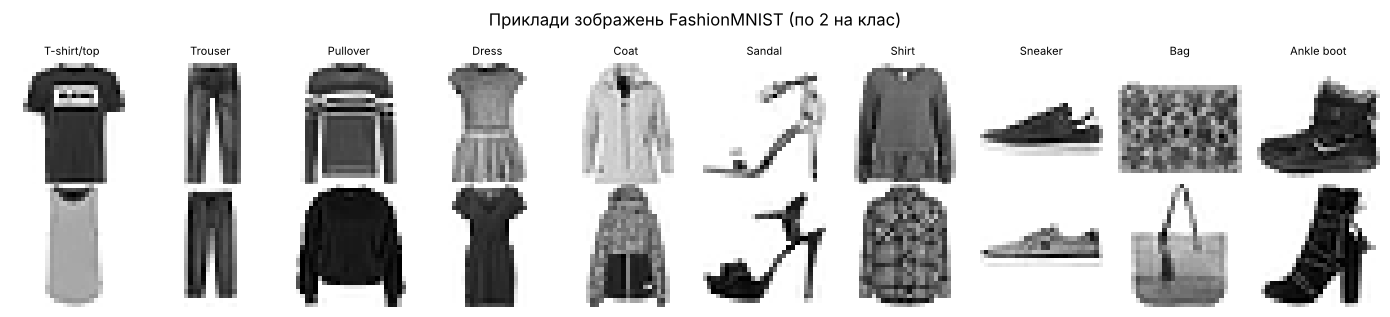

In [2]:
# Шукаємо файли FashionMNIST у кількох місцях: data/fashion/, data/ або поруч із ноутбуком.
# Підходять і стиснуті (.gz, з GitHub Zalando), і розпаковані файли (як на Kaggle).
SEARCH_DIRS = [os.path.join('data', 'fashion'), 'data', '.']
BASE_URL = 'https://github.com/zalandoresearch/fashion-mnist/raw/master/data/fashion/'
DATA_DIR = os.path.join('data', 'fashion')

def find_file(name):
    for d in SEARCH_DIRS:
        for fname in (name, name + '.gz'):
            p = os.path.join(d, fname)
            if os.path.exists(p):
                return p
    return None

def read_idx(name, offset):
    p = find_file(name)
    if p is None:                                   # файлу немає ніде -> завантажуємо з GitHub
        os.makedirs(DATA_DIR, exist_ok=True)
        p = os.path.join(DATA_DIR, name + '.gz')
        print('Завантажую', name + '.gz', '...')
        urllib.request.urlretrieve(BASE_URL + name + '.gz', p)
    opener = gzip.open if p.endswith('.gz') else open
    with opener(p, 'rb') as f:
        data = f.read()
    print('Прочитано:', p)
    return np.frombuffer(data, dtype=np.uint8, offset=offset)

def load_fashion(kind='train'):
    y = read_idx(f'{kind}-labels-idx1-ubyte', offset=8)
    X = read_idx(f'{kind}-images-idx3-ubyte', offset=16).reshape(-1, 784)
    return X, y.astype(np.int64)

X_all, y_all = load_fashion('train')
CLASSES = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
           'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
print('Повний тренувальний набір:', X_all.shape, '| діапазон пікселів:', X_all.min(), '–', X_all.max())

fig, axes = plt.subplots(2, 10, figsize=(14, 3.2))
for c in range(10):
    for r in range(2):
        i = np.where(y_all == c)[0][r]
        axes[r, c].imshow(X_all[i].reshape(28, 28), cmap='gray_r'); axes[r, c].axis('off')
    axes[0, c].set_title(CLASSES[c], fontsize=8)
plt.suptitle('Приклади зображень FashionMNIST (по 2 на клас)'); plt.tight_layout(); plt.show()

**Опис результату.** Повний тренувальний набір FashionMNIST — **60 000 зображень**, кожне вже розгорнуте у вектор із **784** чисел, значення пікселів від 0 до 255. На рисунку по два приклади кожного з 10 класів: футболки, штани, светри, сукні, пальта, сандалі, сорочки, кросівки, сумки, черевики. Видно, що деякі класи дуже схожі між собою (футболка, светр, пальто, сорочка), тому 100% точності тут очікувати не варто.

### Однакові підмножини для всіх експериментів

Щоб експерименти йшли швидко, беремо частину тренувального набору (це дозволено умовою), але **однакову для всіх експериментів**:
- **train:** 20 000 зображень (на них навчаємо і рахуємо мертві нейрони);
- **validation:** 10 000 інших зображень із тренувального набору (на них міряємо якість; під час навчання вони не використовуються).

Перемішування робимо один раз із `SEED`, тому підмножини завжди однакові.

In [3]:
rng = np.random.default_rng(SEED)
perm = rng.permutation(len(X_all))
tr_idx, va_idx = perm[:20000], perm[50000:60000]

X_train = (X_all[tr_idx] / 255.0).astype(np.float32); y_train = y_all[tr_idx]
X_val   = (X_all[va_idx] / 255.0).astype(np.float32); y_val   = y_all[va_idx]

print('X_train:', X_train.shape, '| X_val:', X_val.shape, '| діапазон:', X_train.min(), '–', X_train.max())
counts = pd.DataFrame({'train': np.bincount(y_train, minlength=10), 'val': np.bincount(y_val, minlength=10)}, index=CLASSES)
display(counts.T)

X_train: (20000, 784) | X_val: (10000, 784) | діапазон: 0.0 – 1.0


,T-shirt/top,Trouser,Pullover,Dress,Coat,Sandal,Shirt,Sneaker,Bag,Ankle boot
train,1973,2000,2040,1983,1974,2037,1951,2041,1947,2054
val,977,954,993,1041,1006,995,1024,1010,1011,989


**Опис результату.** У train **20 000** об'єктів, у validation **10 000**, після ділення на 255 значення пікселів лежать у діапазоні **[0, 1]**. Таблиця показує, що класи розподілені майже порівну (≈2000 у train і ≈1000 у validation на кожен клас), тому звичайна accuracy тут є чесною метрикою: дисбалансу немає.

# Блок 1. Реалізація нейронної мережі з нуля

## 1.1 Архітектура та клас `MLP`

**Архітектура:** `784 → 256 → 128 → 64 → 10`
- вхід: 784 пікселі;
- **3 приховані шари** (256, 128 і 64 нейрони) з активацією **ReLU**: `ReLU(z) = max(0, z)`;
- вихід: 10 нейронів (по одному на клас) з **Softmax**, який перетворює числа на ймовірності, що в сумі дають 1.

**Що зберігає клас:** матриці ваг `W⁽ˡ⁾`, вектори зміщень `b⁽ˡ⁾`, проміжні значення `Z⁽ˡ⁾` (до активації) і `A⁽ˡ⁾` (після), а також параметри архітектури (розміри шарів, seed, метод ініціалізації).

**Ініціалізація He:** ваги шару беремо з нормального розподілу N(0, 2/n_in), де n_in — кількість входів шару; зміщення = 0. Така дисперсія підібрана саме під ReLU, щоб сигнал не згасав і не «вибухав» при проходженні шарів.

**Прямий прохід (`forward`):** для кожного шару `Z = A·W + b`, потім `A = ReLU(Z)`; для останнього шару Softmax. Перед експонентою віднімаємо максимум у рядку (`Z − max Z`): результат той самий, але немає переповнення `exp` для великих чисел.

**Зворотний прохід (`backward`):** реалізація формул (6)–(10):
1. для Softmax + cross-entropy градієнт за логітами дорівнює `(P − Y)/N` (у коді: від ймовірності правильного класу віднімаємо 1 і ділимо на розмір батчу);
2. градієнт ваг шару: `Aᵀ_{l−1} · δ_l`, зміщень: сума `δ_l` по батчу;
3. переходимо на шар назад: `δ_{l−1} = (δ_l · W_lᵀ) ⊙ ReLU'(Z_{l−1})`, де ReLU' = 1, якщо z > 0, інакше 0.

**Dropout** (знадобиться в блоці 2): під час навчання після ReLU множимо активації на випадкову маску з 0 і 1/(1−p) (inverted dropout). У backward градієнт множиться на ту саму маску. Під час перевірки (`training=False`) Dropout вимкнений.

**Збереження/відновлення:** `save_weights` записує в один файл `.npz` усі `W_i`, `b_i` і конфігурацію (архітектура, seed, ініціалізація, dropout) у вигляді JSON-рядка; `load_weights` читає їх у новий екземпляр.

In [4]:
class MLP:
    def __init__(self, layer_sizes, seed=SEED, init='he', dtype=np.float32):
        self.layer_sizes = list(layer_sizes)
        self.num_layers = len(layer_sizes) - 1          # кількість шарів з вагами
        self.seed, self.init, self.dtype = seed, init, dtype
        self.dropout_p = 0.0                            # ймовірність вимкнення нейрона
        self.training = False                           # режим навчання (Dropout активний лише тут)
        rng = np.random.default_rng(seed)
        self.weights, self.biases = [], []
        for n_in, n_out in zip(layer_sizes[:-1], layer_sizes[1:]):
            if init == 'he':
                W = rng.standard_normal((n_in, n_out)) * np.sqrt(2.0 / n_in)
            else:                                       # xavier (uniform)
                lim = np.sqrt(6.0 / (n_in + n_out)); W = rng.uniform(-lim, lim, (n_in, n_out))
            self.weights.append(W.astype(dtype)); self.biases.append(np.zeros(n_out, dtype=dtype))
        self.drop_rng = np.random.default_rng(seed + 1)  # окремий генератор для масок Dropout

    def forward(self, X):
        self.activations = [X]; self.z_values = []; self.masks = []
        A = X
        for W, b in zip(self.weights[:-1], self.biases[:-1]):
            Z = A @ W + b
            A = np.maximum(0, Z)                        # ReLU
            M = None
            if self.training and self.dropout_p > 0:    # inverted dropout
                M = (self.drop_rng.random(A.shape) >= self.dropout_p).astype(A.dtype) / (1 - self.dropout_p)
                A = A * M
            self.masks.append(M); self.z_values.append(Z); self.activations.append(A)
        Z = A @ self.weights[-1] + self.biases[-1]
        Z = Z - np.max(Z, axis=1, keepdims=True)        # стабільний softmax
        exp_Z = np.exp(Z)
        P = exp_Z / np.sum(exp_Z, axis=1, keepdims=True)
        self.z_values.append(Z); self.activations.append(P)
        return P

    def backward(self, y_true):
        n = y_true.shape[0]
        grads_W = [None] * self.num_layers; grads_b = [None] * self.num_layers
        delta = self.activations[-1].copy()             # Softmax + Cross-Entropy: (P - Y) / N
        delta[np.arange(n), y_true] -= 1
        delta /= n
        for l in reversed(range(self.num_layers)):
            A_prev = self.activations[l]
            grads_W[l] = A_prev.T @ delta
            grads_b[l] = np.sum(delta, axis=0)
            if l > 0:
                delta = delta @ self.weights[l].T
                if self.masks[l - 1] is not None:       # той самий Dropout-шлях
                    delta = delta * self.masks[l - 1]
                delta = delta * (self.z_values[l - 1] > 0)   # похідна ReLU
        return grads_W, grads_b

    def predict_proba(self, X):
        mode = self.training; self.training = False
        P = self.forward(X); self.training = mode
        return P

    def predict(self, X):
        return self.predict_proba(X).argmax(axis=1)

    def config(self):
        return {'layer_sizes': self.layer_sizes, 'seed': self.seed, 'init': self.init,
                'dtype': np.dtype(self.dtype).name, 'dropout_p': self.dropout_p,
                'activation_hidden': 'relu', 'activation_out': 'softmax'}

    def save_weights(self, path):
        data = {}
        for i, W in enumerate(self.weights): data[f'W_{i}'] = W
        for i, b in enumerate(self.biases):  data[f'b_{i}'] = b
        data['config'] = np.array(json.dumps(self.config()))   # архітектура і параметри як JSON-рядок
        np.savez(path, **data)

    def load_weights(self, path):
        data = np.load(path)
        cfg = json.loads(str(data['config']))
        assert cfg['layer_sizes'] == self.layer_sizes, 'архітектура не збігається'
        self.weights = [data[f'W_{i}'] for i in range(self.num_layers)]
        self.biases  = [data[f'b_{i}'] for i in range(self.num_layers)]
        self.dropout_p = cfg['dropout_p']
        return cfg

    @classmethod
    def from_file(cls, path):
        cfg = json.loads(str(np.load(path)['config']))
        net = cls(cfg['layer_sizes'], seed=cfg['seed'], init=cfg['init'], dtype=np.dtype(cfg['dtype']).type)
        net.load_weights(path)
        return net

ARCH = [784, 256, 128, 64, 10]
net0 = MLP(ARCH)
rows = []
for l, (W, b) in enumerate(zip(net0.weights, net0.biases), 1):
    kind = 'прихований (ReLU)' if l < net0.num_layers else 'вихідний (Softmax)'
    rows.append({'шар': l, 'тип': kind, 'W': str(W.shape), 'b': str(b.shape), 'параметрів': W.size + b.size,
                 'std(W) факт.': round(float(W.std()), 4), 'std за He = √(2/n_in)': round(np.sqrt(2 / W.shape[0]), 4)})
display(pd.DataFrame(rows))
print('Усього параметрів:', sum(r['параметрів'] for r in rows))
P0 = net0.forward(X_train[:5])
print('Перевірка forward: форма', P0.shape, '| суми ймовірностей у рядках:', np.round(P0.sum(1), 6))

,шар,тип,W,b,параметрів,std(W) факт.,std за He = √(2/n_in)
0,1,прихований (ReLU),"(784, 256)","(256,)",200960,0.0506,0.0505
1,2,прихований (ReLU),"(256, 128)","(128,)",32896,0.0880,0.0884
2,3,прихований (ReLU),"(128, 64)","(64,)",8256,0.1235,0.1250
3,4,вихідний (Softmax),"(64, 10)","(10,)",650,0.1772,0.1768


Усього параметрів: 242762
Перевірка forward: форма (5, 10) | суми ймовірностей у рядках: [1. 1. 1. 1. 1.]


**Опис результату.** Мережа має **4 матриці ваг**: три приховані шари 784×256, 256×128, 128×64 і вихідний 64×10, разом **242 762 параметри** (більшість, ≈201 тис., у першому шарі). Стандартні відхилення ваг після ініціалізації (0.0506, 0.0880, 0.1235, 0.1772) майже точно збігаються з теоретичним значенням He √(2/n_in) (0.0505, 0.0884, 0.1250, 0.1768), тобто ініціалізація реалізована правильно. Перевірка прямого проходу: на 5 об'єктах мережа повертає матрицю 5×10, і сума ймовірностей у кожному рядку дорівнює 1, як і має бути після Softmax.

## 1.2 Перевірка градієнтів чисельним диференціюванням

Щоб переконатися, що `backward` рахує похідні **правильно**, порівнюємо їх з чисельною оцінкою:

∂L/∂θ ≈ (L(θ + ε) − L(θ − ε)) / (2ε)

Тобто трохи збільшуємо і трохи зменшуємо один параметр і дивимось, як змінилась втрата. Порівнюємо через **відносну похибку**
E = |g_аналіт − g_чисел| / max(10⁻⁸, |g_аналіт| + |g_чисел|).

Деталі: використовуємо **float64** (у float32 чисельна похідна занадто неточна), маленьку мережу тієї ж будови `784 → 32 → 16 → 8 → 10` і 30 об'єктів; для кожного шару перевіряємо по 6 випадкових ваг і 3 зміщення. Хорошим вважається E < 10⁻⁶ (≈ 10⁻⁷ і менше — відмінно).

In [5]:
def ce_loss(P, y):
    return -np.mean(np.log(P[np.arange(len(y)), y] + 1e-12))

gc_net = MLP([784, 32, 16, 8, 10], seed=SEED, dtype=np.float64)
Xg = X_train[:30].astype(np.float64); yg = y_train[:30]
gc_net.forward(Xg); gW, gb = gc_net.backward(yg)

eps = 1e-5; rng_gc = np.random.default_rng(SEED); rows = []
for l in range(gc_net.num_layers):
    for kind, params, grads, k in [('W', gc_net.weights, gW, 6), ('b', gc_net.biases, gb, 3)]:
        P_ = params[l]
        for _ in range(k):
            idx = tuple(int(rng_gc.integers(0, s)) for s in P_.shape)
            old = P_[idx]
            P_[idx] = old + eps; Lp = ce_loss(gc_net.forward(Xg), yg)
            P_[idx] = old - eps; Lm = ce_loss(gc_net.forward(Xg), yg)
            P_[idx] = old
            num = (Lp - Lm) / (2 * eps); ana = grads[l][idx]
            rel = abs(ana - num) / max(1e-8, abs(ana) + abs(num))
            rows.append({'шар': l + 1, 'параметр': f'{kind}{list(idx)}', 'аналітичний': ana, 'чисельний': num, 'відн. похибка': rel})
gc = pd.DataFrame(rows)
pd.set_option('display.float_format', lambda v: f'{v:.3e}')
display(gc)
pd.reset_option('display.float_format')
print(f"Максимальна відносна похибка: {gc['відн. похибка'].max():.2e} | медіанна: {gc['відн. похибка'].median():.2e}")
print('Кількість нульових градієнтів (ReLU не пропустив сигнал):', int((gc['аналітичний'] == 0).sum()))

,шар,параметр,аналітичний,чисельний,відн. похибка
0,1,"W[69, 24]",2.433e-03,2.433e-03,1.695e-10
1,1,"W[513, 14]",-2.734e-03,-2.734e-03,2.625e-10
2,1,"W[339, 27]",0.000e+00,0.000e+00,0.000e+00
3,1,"W[67, 22]",4.167e-02,4.167e-02,5.920e-10
4,1,"W[157, 3]",5.121e-02,5.121e-02,5.825e-11
5,1,"W[412, 31]",-9.590e-03,-9.590e-03,2.743e-09
6,1,b[23],-2.489e-02,-2.489e-02,2.729e-10
7,1,b[24],2.603e-02,2.603e-02,1.723e-10
8,1,b[22],3.140e-02,3.140e-02,3.735e-10
9,2,"W[25, 8]",1.611e-04,1.611e-04,3.890e-08


Максимальна відносна похибка: 3.89e-08 | медіанна: 1.71e-10
Кількість нульових градієнтів (ReLU не пропустив сигнал): 7


**Опис результату.** Для всіх 36 перевірених параметрів аналітичний градієнт (з `backward`) і чисельний збігаються. **Максимальна відносна похибка ≈ 3,89·10⁻⁸, медіанна ≈ 1,71·10⁻¹⁰**, тобто набагато менше за поріг 10⁻⁶. Отже, backpropagation реалізовано правильно.

7 градієнтів дорівнюють рівно нулю (і аналітично, і чисельно). Це не помилка: такі ваги ведуть до нейрона, який на цих 30 об'єктах не активувався (Z ≤ 0), а похідна ReLU там 0, тож сигнал крізь нього не проходить.

## 1.3 Цикл навчання

Функція `train` реалізує повний цикл:
1. на кожній епосі **перемішуємо** тренувальні дані (генератор з фіксованим seed, тому порядок однаковий в усіх експериментах);
2. ділимо на **мінібатчі** по 64 об'єкти;
3. **прямий прохід** → 4. **втрата** (cross-entropy) → 5. **backward**;
6. **оновлення** `W ← W − η·∇W`, `b ← b − η·∇b` (звичайний SGD).

Сюди ж одразу вбудовано опції для блоку 2 (за замовчуванням вимкнені):
- `l2`: до градієнта ваг додаємо `λ₂·W` (формула 33);
- `l1`: додаємо `λ₁·sign(W)` (субградієнт; `np.sign(0) = 0`, як вимагає умова);
- `dropout`: ймовірність вимкнення нейронів у прихованих шарах;
- `wclip`: після кожного кроку обрізаємо ваги до [−c, c];
- `gclip`: якщо **глобальна L2-норма** всіх градієнтів більша за c, масштабуємо їх усі, щоб норма стала c (формула 38).

Регуляризація застосовується лише до ваг, а не до зміщень (так прийнято).

**Швидкість навчання:** η = 0.05 з поступовим зменшенням ×0.93 на кожній епосі (η_епоха = 0.05·0.93^епоха). Це звичайний SGD, лише крок поступово меншає, щоб наприкінці навчання точність не «скакала» від епохи до епохи і результати експериментів можна було чесно порівнювати. 30 епох.

Після кожної епохи (з **вимкненим** Dropout) рахуємо loss і accuracy на train і validation. Loss на графіках — це **чиста cross-entropy** без штрафу, щоб її можна було порівнювати між методами.

In [6]:
EPOCHS, LR, DECAY, BATCH = 30, 0.05, 0.93, 64

def train(net, X_tr, y_tr, X_va, y_va, epochs=EPOCHS, lr=LR, decay=DECAY, batch_size=BATCH,
          l1=0.0, l2=0.0, dropout=0.0, wclip=None, gclip=None, seed=SEED, verbose=False):
    rng = np.random.default_rng(seed)                 # однаковий порядок батчів для всіх експериментів
    net.dropout_p = dropout
    hist = {k: [] for k in ['train_loss', 'train_acc', 'val_loss', 'val_acc', 'grad_norm', 'clip_frac', 'batch_loss']}
    for ep in range(epochs):
        eta = lr * decay ** ep
        perm = rng.permutation(len(X_tr))
        net.training = True; norms, clipped = [], 0
        for s in range(0, len(perm), batch_size):
            b = perm[s:s + batch_size]
            P = net.forward(X_tr[b])
            hist['batch_loss'].append(ce_loss(P, y_tr[b]))
            gW, gb = net.backward(y_tr[b])
            for l in range(net.num_layers):             # регуляризація (тільки ваги)
                if l2: gW[l] = gW[l] + l2 * net.weights[l]
                if l1: gW[l] = gW[l] + l1 * np.sign(net.weights[l])
            gnorm = float(np.sqrt(sum(np.sum(g * g) for g in gW + gb)))
            norms.append(gnorm)
            if gclip is not None and gnorm > gclip:     # gradient clipping за глобальною нормою
                f = gclip / gnorm; gW = [g * f for g in gW]; gb = [g * f for g in gb]; clipped += 1
            for l in range(net.num_layers):             # SGD
                net.weights[l] -= eta * gW[l]
                net.biases[l]  -= eta * gb[l]
                if wclip is not None:                   # weight clipping
                    np.clip(net.weights[l], -wclip, wclip, out=net.weights[l])
        net.training = False
        P = net.forward(X_tr); hist['train_loss'].append(ce_loss(P, y_tr)); hist['train_acc'].append(np.mean(P.argmax(1) == y_tr))
        P = net.forward(X_va); hist['val_loss'].append(ce_loss(P, y_va));   hist['val_acc'].append(np.mean(P.argmax(1) == y_va))
        hist['grad_norm'].append(np.median(norms)); hist['clip_frac'].append(clipped / len(norms))
        if verbose and (ep % 5 == 4 or ep == 0):
            print(f"епоха {ep+1:2d}: train loss {hist['train_loss'][-1]:.4f} acc {hist['train_acc'][-1]:.4f} | "
                  f"val loss {hist['val_loss'][-1]:.4f} acc {hist['val_acc'][-1]:.4f} | медіана ||g|| {hist['grad_norm'][-1]:.3f}")
    return hist

def plot_history(hist, title):
    ep = np.arange(1, len(hist['train_loss']) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(ep, hist['train_loss'], label='train'); ax[0].plot(ep, hist['val_loss'], label='validation')
    ax[0].set_xlabel('епоха'); ax[0].set_ylabel('cross-entropy'); ax[0].set_title(f'{title}: функція втрат'); ax[0].legend()
    ax[1].plot(ep, hist['train_acc'], label='train'); ax[1].plot(ep, hist['val_acc'], label='validation')
    ax[1].set_xlabel('епоха'); ax[1].set_ylabel('accuracy'); ax[1].set_title(f'{title}: accuracy'); ax[1].legend()
    plt.tight_layout(); plt.show()
print('Функції train і plot_history готові')

Функції train і plot_history готові


### Навчання базової мережі та графіки навчання

Навчаємо мережу **без регуляризації**. Вона ж буде базовим експериментом у блоці 2. Окремо зберігаємо копію **початкових ваг** (після He-ініціалізації), щоб потім порівняти розподіл ваг «до» і «після».

епоха  1: train loss 0.5643 acc 0.7993 | val loss 0.5848 acc 0.7890 | медіана ||g|| 2.347


епоха  5: train loss 0.4001 acc 0.8504 | val loss 0.4462 acc 0.8340 | медіана ||g|| 1.923


епоха 10: train loss 0.3201 acc 0.8842 | val loss 0.3985 acc 0.8590 | медіана ||g|| 1.819


епоха 15: train loss 0.2666 acc 0.9030 | val loss 0.3615 acc 0.8703 | медіана ||g|| 1.929


епоха 20: train loss 0.2300 acc 0.9170 | val loss 0.3431 acc 0.8766 | медіана ||g|| 1.865


епоха 25: train loss 0.2108 acc 0.9261 | val loss 0.3420 acc 0.8802 | медіана ||g|| 1.975


епоха 30: train loss 0.2006 acc 0.9312 | val loss 0.3395 acc 0.8777 | медіана ||g|| 1.988
Час навчання: 14.8 с


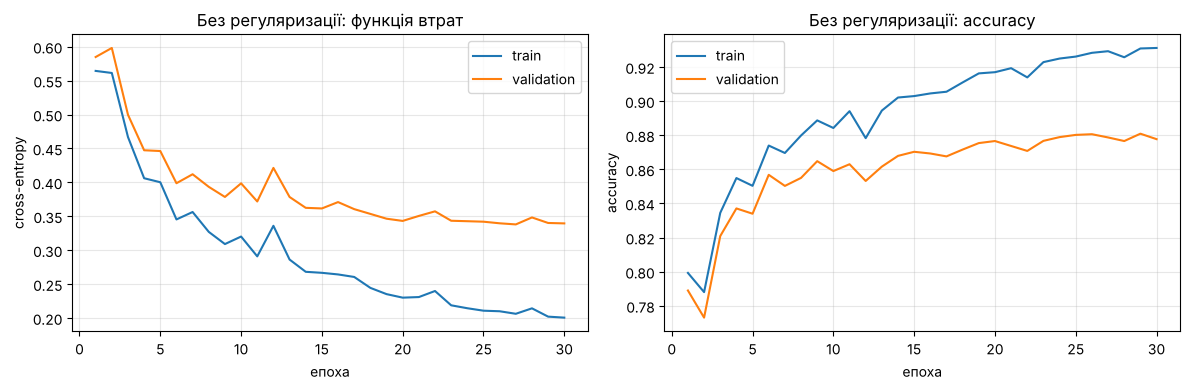

Фінал: train acc 0.9312, val acc 0.8777, train loss 0.2006, val loss 0.3395
Найнижча val loss 0.3380 на епосі 27


In [7]:
base_net = MLP(ARCH)
W_init = [W.copy() for W in base_net.weights]           # ваги одразу після He-ініціалізації
t0 = time.time()
base_hist = train(base_net, X_train, y_train, X_val, y_val, verbose=True)
print(f'Час навчання: {time.time() - t0:.1f} с')
plot_history(base_hist, 'Без регуляризації')
print(f"Фінал: train acc {base_hist['train_acc'][-1]:.4f}, val acc {base_hist['val_acc'][-1]:.4f}, "
      f"train loss {base_hist['train_loss'][-1]:.4f}, val loss {base_hist['val_loss'][-1]:.4f}")
print(f"Найнижча val loss {min(base_hist['val_loss']):.4f} на епосі {int(np.argmin(base_hist['val_loss'])) + 1}")

**Опис результату (графіки навчання базової мережі).**
- **Втрати:** обидві криві швидко падають у перші 5–6 епох (з ≈0.57–0.6 до ≈0.4), далі train loss продовжує знижуватися аж до **0.20**, а validation loss «застигає» на рівні **≈0.34** (мінімум 0.338 на 27-й епосі).
- **Accuracy:** train зростає до **0.931**, validation до **0.878**.
- Між train і validation з'являється **розрив ≈5.3 п.п.** Це помірне **перенавчання**: модель трохи запам'ятовує тренувальні дані. Але validation loss не зростає різко, тож перенавчання не сильне.
- Невеликі «зубці» на кривих (наприклад, на 2-й, 12-й, 22-й епохах) — це звичайний шум стохастичного градієнтного спуску; ближче до кінця крок навчання стає меншим, і криві згладжуються.

Навчання 30 епох зайняло приблизно 15 секунд.

## 1.4 Збереження та відновлення ваг

Перевіряємо механізм за 6 кроками з умови:
1. мережу вже навчено (`base_net`);
2. зберігаємо ваги у файл `mlp_baseline.npz`;
3. створюємо **новий** екземпляр тієї ж архітектури (з іншим seed, щоб початкові ваги точно були іншими);
4. завантажуємо в нього збережені ваги;
5. подаємо однакові дані (усю валідаційну вибірку) обом мережам;
6. порівнюємо ймовірності й передбачені класи. Має бути max|P_orig − P_restored| < 10⁻⁷.

Додатково показуємо, що відновлюється й конфігурація (архітектура, ініціалізація), і що `MLP.from_file` створює мережу прямо з файлу.

In [8]:
path = 'mlp_baseline.npz'
base_net.save_weights(path)
print('Файл:', path, '| розмір:', round(os.path.getsize(path) / 1024, 1), 'КБ | ключі:', list(np.load(path).keys()))

restored = MLP(ARCH, seed=999)                            # інші початкові ваги
P_before = restored.predict_proba(X_val)
cfg = restored.load_weights(path)
print('Відновлена конфігурація:', cfg)

P_orig = base_net.predict_proba(X_val); P_rest = restored.predict_proba(X_val)
print(f'До завантаження: max|P_orig − P_new| = {np.abs(P_orig - P_before).max():.4f}')
print(f'Після завантаження: max|P_orig − P_restored| = {np.abs(P_orig - P_rest).max():.2e}  (умова < 1e-7: {np.abs(P_orig - P_rest).max() < 1e-7})')
print('Передбачені класи збігаються на всіх', len(X_val), 'об\'єктах:', bool(np.all(P_orig.argmax(1) == P_rest.argmax(1))))
net_ff = MLP.from_file(path)
print('MLP.from_file: max різниця =', np.abs(net_ff.predict_proba(X_val) - P_orig).max(), '| val acc =', round(float(np.mean(net_ff.predict(X_val) == y_val)), 4))

Файл: mlp_baseline.npz | розмір: 951.0 КБ | ключі: ['W_0', 'W_1', 'W_2', 'W_3', 'b_0', 'b_1', 'b_2', 'b_3', 'config']


Відновлена конфігурація: {'layer_sizes': [784, 256, 128, 64, 10], 'seed': 42, 'init': 'he', 'dtype': 'float32', 'dropout_p': 0.0, 'activation_hidden': 'relu', 'activation_out': 'softmax'}
До завантаження: max|P_orig − P_new| = 0.9697
Після завантаження: max|P_orig − P_restored| = 0.00e+00  (умова < 1e-7: True)
Передбачені класи збігаються на всіх 10000 об'єктах: True


MLP.from_file: max різниця = 0.0 | val acc = 0.8777


**Опис результату.** Файл `mlp_baseline.npz` (≈951 КБ) містить 4 матриці ваг `W_0…W_3`, 4 вектори зміщень `b_0…b_3` і рядок `config` з архітектурою, seed, методом ініціалізації та іншими параметрами.
- До завантаження нова мережа (інші випадкові ваги) давала зовсім інші ймовірності: різниця до **0.97**.
- Після завантаження різниця **max|P_orig − P_restored| = 0** (умова < 10⁻⁷ виконана), і передбачені класи збігаються на **всіх 10 000** об'єктах.
- `MLP.from_file` відновлює мережу прямо з файлу, і вона має ту саму точність **0.8777**.

Отже, збереження та відновлення працює коректно.

# Блок 2. Дослідження впливу регуляризації

## 2.1 Інструменти вимірювання

Для кожної навченої мережі рахуємо:
- **мертві нейрони** (формули 30–31): нейрон шару l мертвий, якщо його передактивація Z ≤ 0 **для всіх** 20 000 тренувальних об'єктів, тобто max по об'єктах ≤ 0. Рахуємо в режимі inference (**Dropout вимкнено**), щоб нейрони, випадково вимкнені маскою, не вважалися мертвими;
- **sparsity** (формула 24): частка ваг з |w| < 0.01 серед **усіх** ваг мережі (і окремо по шарах);
- **validation accuracy** і **validation loss** (cross-entropy) після останньої епохи;
- для weight clipping додатково: скільки ваг «упираються» в межі ±c.

Функція `run_experiment` навчає мережу з заданими налаштуваннями (завжди з тих самих початкових ваг і на тих самих батчах) і записує всі ці показники в таблицю `RESULTS`.

In [9]:
HIDDEN = ARCH[1:-1]                                   # [256, 128, 64]
def dead_neurons(net, X):
    net.training = False; net.forward(X)
    return [int(np.sum(Z.max(axis=0) <= 0)) for Z in net.z_values[:-1]]

def sparsity(weights, thr=0.01):
    w = np.concatenate([W.ravel() for W in weights]); return float(np.mean(np.abs(w) < thr) * 100)

RESULTS, NETS, HISTS = {}, {}, {}
def run_experiment(name, params_text='—', **cfg):
    net = MLP(ARCH)                                   # ті самі початкові ваги (SEED)
    t0 = time.time(); hist = train(net, X_train, y_train, X_val, y_val, **cfg)
    dead = dead_neurons(net, X_train)
    row = {'Метод': name, 'Параметри': params_text,
           'Dead neurons, %': 100 * sum(dead) / sum(HIDDEN),
           **{f'dead L{i+1}': d for i, d in enumerate(dead)},
           'Sparsity, %': sparsity(net.weights),
           **{f'sparsity W{i+1}, %': sparsity([W]) for i, W in enumerate(net.weights)},
           'Train acc': hist['train_acc'][-1], 'Val. accuracy': hist['val_acc'][-1], 'Val. loss': hist['val_loss'][-1],
           'max|W|': max(float(np.abs(W).max()) for W in net.weights), 'час, с': time.time() - t0}
    if cfg.get('wclip') is not None:
        c = cfg['wclip']; w = np.concatenate([W.ravel() for W in net.weights])
        row['ваг на межі ±c'] = int(np.sum(np.abs(w) >= c - 1e-7)); row['ваг на межі, %'] = 100 * row['ваг на межі ±c'] / w.size
    if cfg.get('gclip') is not None:
        row['частка обрізаних кроків, %'] = 100 * float(np.mean(hist['clip_frac']))
    RESULTS[name], NETS[name], HISTS[name] = row, net, hist
    return row

def show(names, cols=('Параметри', 'Dead neurons, %', 'dead L1', 'dead L2', 'dead L3', 'Sparsity, %', 'Train acc', 'Val. accuracy', 'Val. loss')):
    df = pd.DataFrame([RESULTS[n] for n in names]).set_index('Метод')
    cols = [c for c in cols if c in df.columns]
    display(df[list(cols)].round(4))

def hidden_w(net): return [net.weights[i] for i in range(len(HIDDEN))]   # ваги прихованих шарів W1..W3

def plot_hists(names, title, logy=True, xlim=None, bins=120):
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    for i, ax in enumerate(axes):
        ax.hist(W_init[i].ravel(), bins=bins, histtype='step', lw=1.5, color='gray', label='He-ініціалізація', density=True)
        ax.hist(NETS['Без регуляризації'].weights[i].ravel(), bins=bins, histtype='step', lw=1.5, color='black', label='без регуляризації', density=True)
        for n in names:
            ax.hist(NETS[n].weights[i].ravel(), bins=bins, histtype='step', lw=1.3, label=n, density=True)
        ax.set_title(f'{title}: шар {i+1} ({W_init[i].shape[0]}×{W_init[i].shape[1]})'); ax.set_xlabel('значення ваги')
        if logy: ax.set_yscale('log')
        if xlim: ax.set_xlim(*xlim)
    axes[0].set_ylabel('щільність' + (' (log)' if logy else ''))
    axes[-1].legend(fontsize=8); plt.tight_layout(); plt.show()
print('Інструменти готові')

Інструменти готові


## 2.2 Базовий експеримент (без регуляризації) і діагностика мертвих нейронів

Базова мережа навчена вище. Тепер для неї рахуємо всі показники, будуємо **таблицю мертвих нейронів по шарах** і **гістограми ваг** кожного прихованого шару до і після навчання.

Val. accuracy = 0.8777 | Val. loss = 0.3395 | Train acc = 0.9312
Мертві нейрони (передактивація ≤ 0 для всіх 20 000 тренувальних об'єктів):


,шар,нейронів,мертвих,"частка, %"
0,1,256,0,0.00
1,2,128,0,0.00
2,3,64,1,1.56


,матриця,"sparsity після He-ініціалізації, %","sparsity після навчання, %",std до,std після,max|W| після
0,"W1 (784, 256)",15.6733,15.2159,0.0506,0.0522,0.2541
1,"W2 (256, 128)",9.0179,8.8409,0.0880,0.0918,0.4072
2,"W3 (128, 64)",6.4941,5.9570,0.1235,0.1337,0.5610
3,"W4 (64, 10)",4.5312,3.1250,0.1772,0.2563,0.8069


Sparsity усіх ваг: до навчання 14.43%, після 14.01%


Нейрони, активні менш ніж на 1% об'єктів (по шарах): [6, 5, 7]


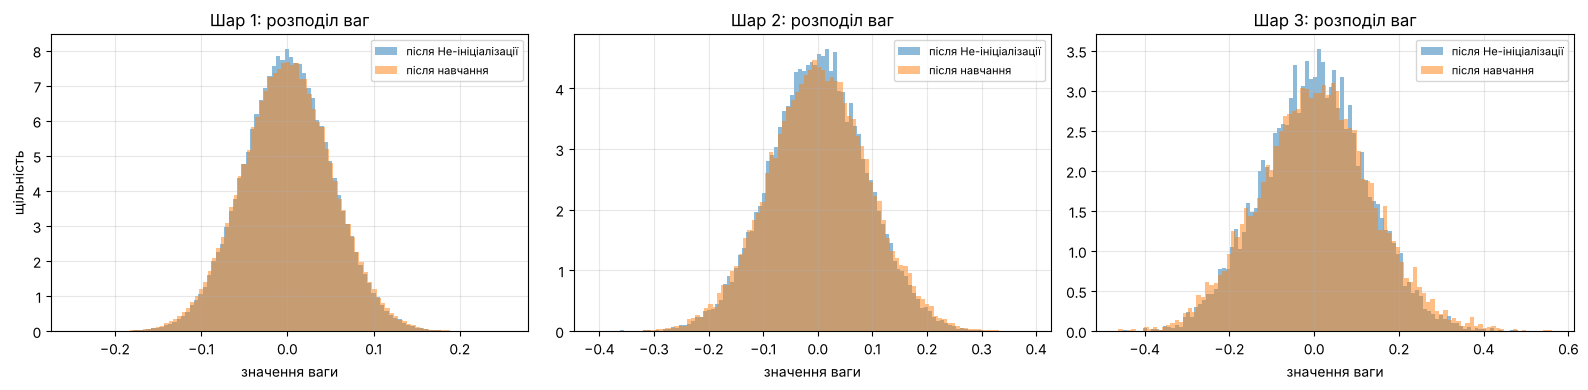

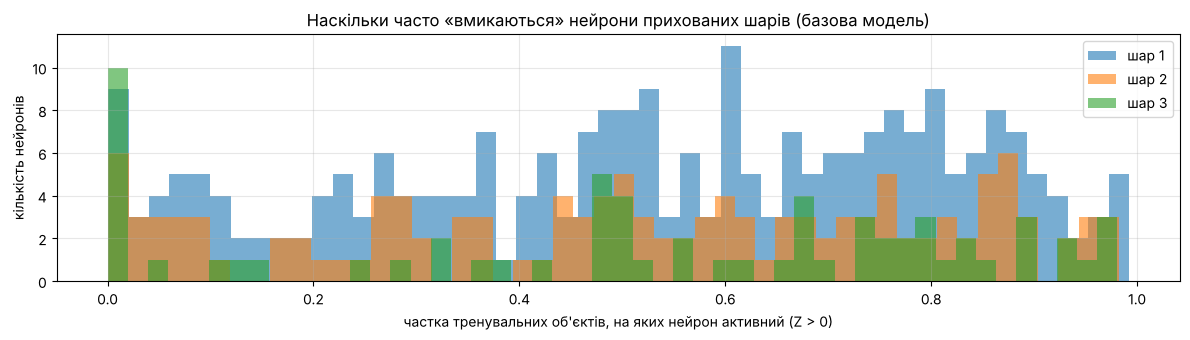

In [10]:
dead = dead_neurons(base_net, X_train)
row = {'Метод': 'Без регуляризації', 'Параметри': '—', 'Dead neurons, %': 100 * sum(dead) / sum(HIDDEN),
       **{f'dead L{i+1}': d for i, d in enumerate(dead)}, 'Sparsity, %': sparsity(base_net.weights),
       **{f'sparsity W{i+1}, %': sparsity([W]) for i, W in enumerate(base_net.weights)},
       'Train acc': base_hist['train_acc'][-1], 'Val. accuracy': base_hist['val_acc'][-1], 'Val. loss': base_hist['val_loss'][-1],
       'max|W|': max(float(np.abs(W).max()) for W in base_net.weights), 'час, с': np.nan}
RESULTS['Без регуляризації'], NETS['Без регуляризації'], HISTS['Без регуляризації'] = row, base_net, base_hist

print(f"Val. accuracy = {row['Val. accuracy']:.4f} | Val. loss = {row['Val. loss']:.4f} | Train acc = {row['Train acc']:.4f}")
dead_tab = pd.DataFrame({'шар': [1, 2, 3], 'нейронів': HIDDEN, 'мертвих': dead,
                         'частка, %': [100 * d / n for d, n in zip(dead, HIDDEN)]})
print('Мертві нейрони (передактивація ≤ 0 для всіх 20 000 тренувальних об\'єктів):')
display(dead_tab.round(2))

sp_tab = pd.DataFrame({'матриця': [f'W{i+1} {W.shape}' for i, W in enumerate(base_net.weights)],
                       'sparsity після He-ініціалізації, %': [sparsity([W]) for W in W_init],
                       'sparsity після навчання, %': [sparsity([W]) for W in base_net.weights],
                       'std до': [float(W.std()) for W in W_init], 'std після': [float(W.std()) for W in base_net.weights],
                       'max|W| після': [float(np.abs(W).max()) for W in base_net.weights]})
display(sp_tab.round(4))
print(f"Sparsity усіх ваг: до навчання {sparsity(W_init):.2f}%, після {sparsity(base_net.weights):.2f}%")

# скільки нейронів «майже мертві»: активні лише на дуже малій частці об'єктів
base_net.forward(X_train)
act_share = [np.mean(Z > 0, axis=0) for Z in base_net.z_values[:-1]]
print('Нейрони, активні менш ніж на 1% об\'єктів (по шарах):', [int(np.sum(a < 0.01)) for a in act_share])

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for i, ax in enumerate(axes):
    ax.hist(W_init[i].ravel(), bins=100, alpha=0.5, label='після He-ініціалізації', density=True)
    ax.hist(base_net.weights[i].ravel(), bins=100, alpha=0.5, label='після навчання', density=True)
    ax.set_title(f'Шар {i+1}: розподіл ваг'); ax.set_xlabel('значення ваги'); ax.legend(fontsize=8)
axes[0].set_ylabel('щільність'); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(12, 3.5))
for i, a in enumerate(act_share):
    ax.hist(a, bins=50, alpha=0.6, label=f'шар {i+1}')
ax.set_xlabel('частка тренувальних об\'єктів, на яких нейрон активний (Z > 0)'); ax.set_ylabel('кількість нейронів')
ax.set_title('Наскільки часто «вмикаються» нейрони прихованих шарів (базова модель)'); ax.legend(); plt.tight_layout(); plt.show()

**Опис результату (базовий експеримент).**
- **Якість:** validation accuracy **0.8777**, validation loss **0.3395** (train accuracy 0.9312).
- **Мертві нейрони:** лише **1 з 448** (один нейрон у третьому шарі, 1.56% цього шару; у шарах 1 і 2 мертвих немає). Тобто без регуляризації проблема мертвих нейронів майже не виникає.
- **Sparsity:** **14.0%** усіх ваг мають |w| < 0.01. Але **до навчання їх було 14.4%**! Отже, майже всі «малі» ваги з'явилися ще при ініціалізації He: у першому шарі std ваг ≈0.05, тож багато ваг випадково близькі до нуля (15.7%). Навчання майже не змінило цю частку.
- **Розподіл ваг (перший рисунок):** розподіли до і після навчання майже збігаються (дзвоноподібні, центровані в нулі); після навчання вони трохи ширші (std шару 3 зросла з 0.124 до 0.134) — ваги трохи «розійшлися» від нуля, щоб модель могла розрізняти класи. Найбільша вага всієї мережі за модулем 0.81 (у вихідному шарі).
- **Другий рисунок:** як часто вмикається кожен нейрон. Більшість нейронів активні на 20–90% об'єктів (це нормально), але є група нейронів **біля нуля**: 6, 5 і 7 нейронів (по шарах) активуються менш ніж на 1% об'єктів. Вони ще не мертві, але «майже мертві»: відповідають лише на рідкісні зображення.

## 2.3 L2 регуляризація

До функції втрат додається штраф (λ₂/2)·Σ‖W‖², тобто до градієнта ваг на кожному кроці додається λ₂·W. Простими словами: кожна вага трохи «тягнеться до нуля» пропорційно своєму розміру (великі — сильніше). Тому L2 ще називають **weight decay**.

Перевіряємо три значення: **λ₂ ∈ {10⁻⁴, 10⁻³, 10⁻²}** (слабка, середня, сильна).

,Параметри,"Dead neurons, %",dead L1,dead L2,dead L3,"Sparsity, %",Train acc,Val. accuracy,Val. loss
Метод,,,,,,,,,
Без регуляризації,—,0.2232,0,0,1,14.0088,0.9312,0.8777,0.3395
L2 λ=0.0001,λ2 = 0.0001,0.4464,0,0,2,14.2697,0.9308,0.8780,0.3371
L2 λ=0.001,λ2 = 0.001,0.4464,0,0,2,16.9172,0.9198,0.8750,0.3369
L2 λ=0.01,λ2 = 0.01,3.1250,0,6,8,62.9771,0.8670,0.8523,0.4320


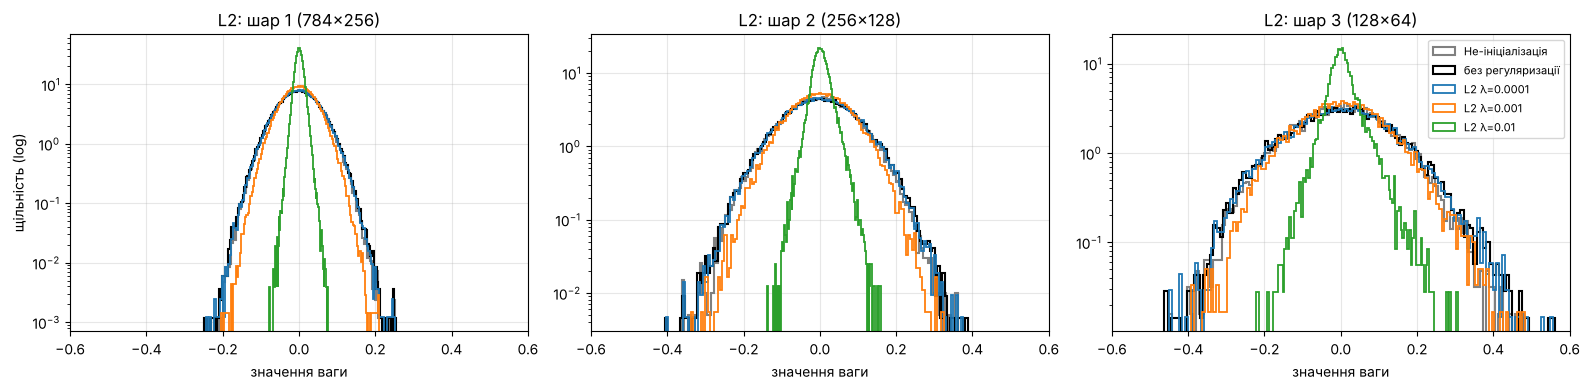

In [11]:
for lam in [1e-4, 1e-3, 1e-2]:
    run_experiment(f'L2 λ={lam:g}', f'λ2 = {lam:g}', l2=lam)
L2_NAMES = [n for n in RESULTS if n.startswith('L2 λ')]
show(['Без регуляризації'] + L2_NAMES)
plot_hists(L2_NAMES, 'L2', xlim=(-0.6, 0.6))

**Опис результату (L2).**
- **λ₂ = 10⁻⁴:** майже нічого не змінилося: accuracy 0.8780 (як базова), sparsity 14.3%, мертвих 2.
- **λ₂ = 10⁻³:** accuracy 0.8750 (трохи нижче), але validation loss **0.3369** — менший, ніж у базовій (0.3395); розрив train−val зменшився з 5.3 до 4.5 п.п. Sparsity зросла до 16.9%.
- **λ₂ = 10⁻²:** сильна регуляризація: accuracy впала до **0.8523**, train accuracy лише 0.867 (модель **недонавчилась**), **63%** ваг стали майже нульовими, мертвих нейронів **14** (6 у шарі 2 і 8 у шарі 3).

**Гістограми:** що більша λ₂, то **вужчий** розподіл ваг: ваги «стягуються» до нуля, а великі значення зникають (при λ₂ = 10⁻² майже немає ваг за межами ±0.2 у першому шарі). Форма розподілу лишається гладкою «горою» без гострого піку в нулі: L2 **зменшує** ваги, але не робить їх точно нульовими.

## 2.4 L1 регуляризація

Штраф λ₁·Σ|W|, тобто до градієнта додається λ₁·sign(W) (у нулі субградієнт = 0). На відміну від L2, ця «сила» **однакова для малих і великих ваг**, тому малі ваги легко доштовхуються до нуля: L1 створює **розріджені** матриці (багато нулів).

Перевіряємо **λ₁ ∈ {10⁻⁵, 10⁻⁴, 10⁻³}**.

,Параметри,"Dead neurons, %",dead L1,dead L2,dead L3,"Sparsity, %",Train acc,Val. accuracy,Val. loss
Метод,,,,,,,,,
Без регуляризації,—,0.2232,0,0,1,14.0088,0.9312,0.8777,0.3395
L1 λ=1e-05,λ1 = 1e-05,0.2232,0,0,1,16.5036,0.9320,0.8793,0.3350
L1 λ=0.0001,λ1 = 0.0001,0.4464,0,0,2,39.3114,0.9176,0.8757,0.3370
L1 λ=0.001,λ1 = 0.001,13.6161,38,15,8,97.6294,0.8435,0.8335,0.4753


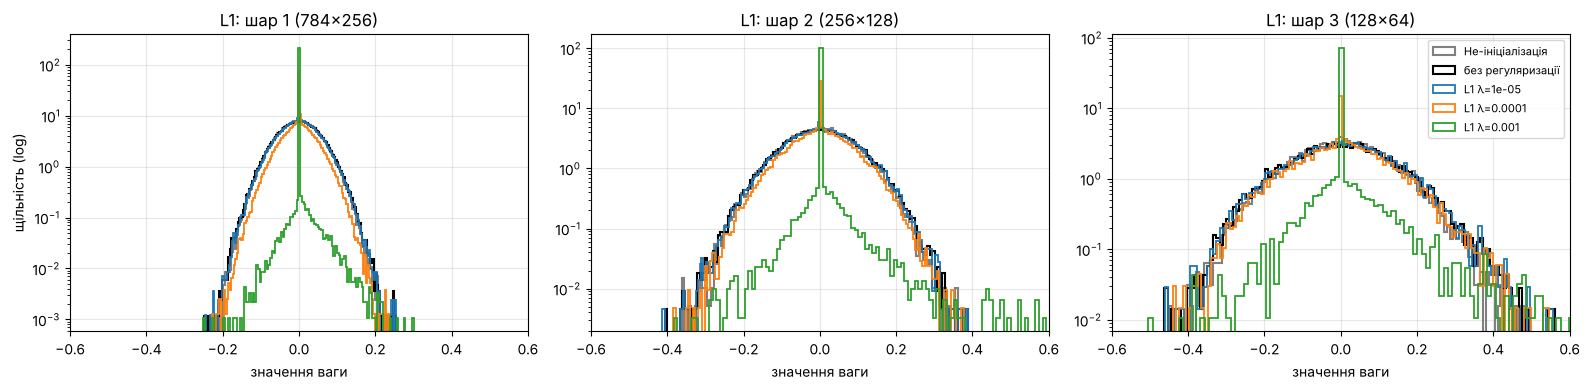

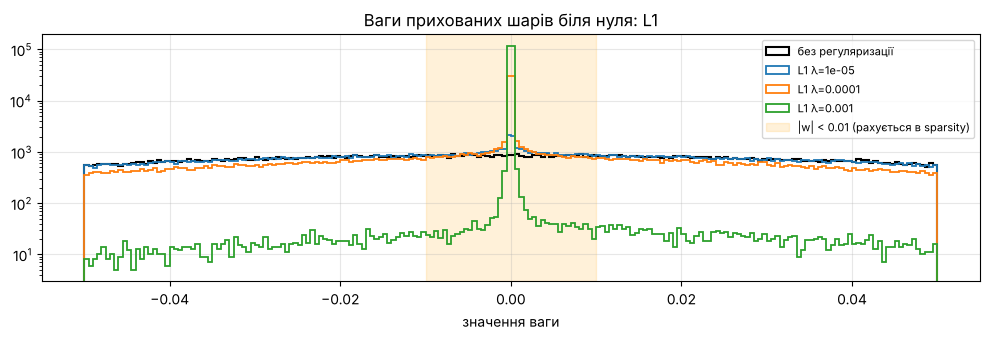

In [12]:
for lam in [1e-5, 1e-4, 1e-3]:
    run_experiment(f'L1 λ={lam:g}', f'λ1 = {lam:g}', l1=lam)
L1_NAMES = [n for n in RESULTS if n.startswith('L1 λ')]
show(['Без регуляризації'] + L1_NAMES)
plot_hists(L1_NAMES, 'L1', xlim=(-0.6, 0.6))

# крупний план біля нуля
fig, ax = plt.subplots(figsize=(10, 3.5))
w0 = np.concatenate([W.ravel() for W in hidden_w(NETS['Без регуляризації'])])
ax.hist(w0, bins=200, range=(-0.05, 0.05), histtype='step', lw=1.5, color='black', label='без регуляризації')
for n in L1_NAMES:
    ax.hist(np.concatenate([W.ravel() for W in hidden_w(NETS[n])]), bins=200, range=(-0.05, 0.05), histtype='step', lw=1.3, label=n)
ax.axvspan(-0.01, 0.01, color='orange', alpha=0.15, label='|w| < 0.01 (рахується в sparsity)')
ax.set_yscale('log'); ax.set_xlabel('значення ваги'); ax.set_title('Ваги прихованих шарів біля нуля: L1'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Опис результату (L1).**
- **λ₁ = 10⁻⁵:** accuracy **0.8793** — найкраща серед усіх експериментів, validation loss 0.3350 (теж найменша). Але перевага над базовою (+0.16 п.п., ≈16 об'єктів із 10 000) дуже мала й може бути випадковою. Sparsity зросла до 16.5%.
- **λ₁ = 10⁻⁴:** sparsity **39.3%**, а точність майже та сама (**0.8757**). Тобто майже 40% ваг можна «занулити» без втрати якості. Мертвих нейронів лише 2.
- **λ₁ = 10⁻³:** надмірна регуляризація: **97.6%** ваг майже нульові, **61 мертвий нейрон** (38 у шарі 1, 15 у шарі 2, 8 у шарі 3, разом 13.6%), accuracy впала до **0.8335**.

**Гістограми:** на відміну від L2, у L1 з'являється **гострий пік рівно в нулі**, а «плечі» розподілу зникають. При λ₁ = 10⁻³ майже всі ваги в нулі, але **кілька ваг залишаються великими** (max|w| = 0.86): мережа зберігає лише найважливіші зв'язки. На графіку крупним планом (|w| < 0.05) видно, як зі збільшенням λ₁ ваги збираються в нулі (зафарбована зона |w| < 0.01 — це те, що рахується в sparsity).

Це і є відома властивість L1: вона створює **розріджені** (sparse) матриці ваг, а L2 — просто малі.

## 2.5 Dropout

Під час навчання кожен нейрон прихованих шарів з ймовірністю p **тимчасово вимикається** (його вихід = 0), а решта виходів множиться на 1/(1−p) (inverted dropout), щоб середній сигнал не змінився. Мережа не може покладатися на окремі нейрони й вчиться бути стійкою. На перевірці Dropout вимкнений.

Експерименти: **p ∈ {0.1, 0.3, 0.5}** (окремо додаємо ще p = 0.2: він знадобиться для порівняння з комбінацією L2 + Dropout 0.2). Крім таблиці й гістограм, показуємо криві навчання: Dropout має зменшити **розрив між train і validation**.

,Параметри,"Dead neurons, %",dead L1,dead L2,dead L3,"Sparsity, %",Train acc,Val. accuracy,Val. loss
Метод,,,,,,,,,
Без регуляризації,—,0.2232,0,0,1,14.0088,0.9312,0.8777,0.3395
Dropout 0.1,p = 0.1,0.0000,0,0,0,14.0683,0.9171,0.8760,0.3377
Dropout 0.3,p = 0.3,0.0000,0,0,0,14.0980,0.8966,0.8717,0.3590
Dropout 0.5,p = 0.5,0.0000,0,0,0,14.1488,0.8683,0.8515,0.4251
Dropout 0.2,p = 0.2,0.0000,0,0,0,14.0373,0.9058,0.8719,0.3488


Без регуляризації  розрив train−val accuracy = +0.0534
Dropout 0.1        розрив train−val accuracy = +0.0411
Dropout 0.3        розрив train−val accuracy = +0.0249
Dropout 0.5        розрив train−val accuracy = +0.0168


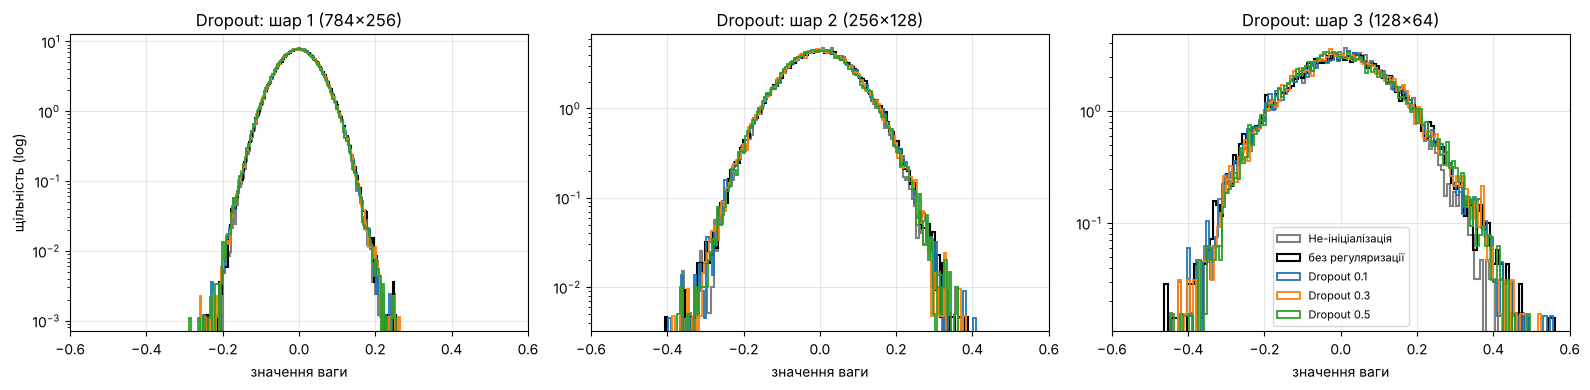

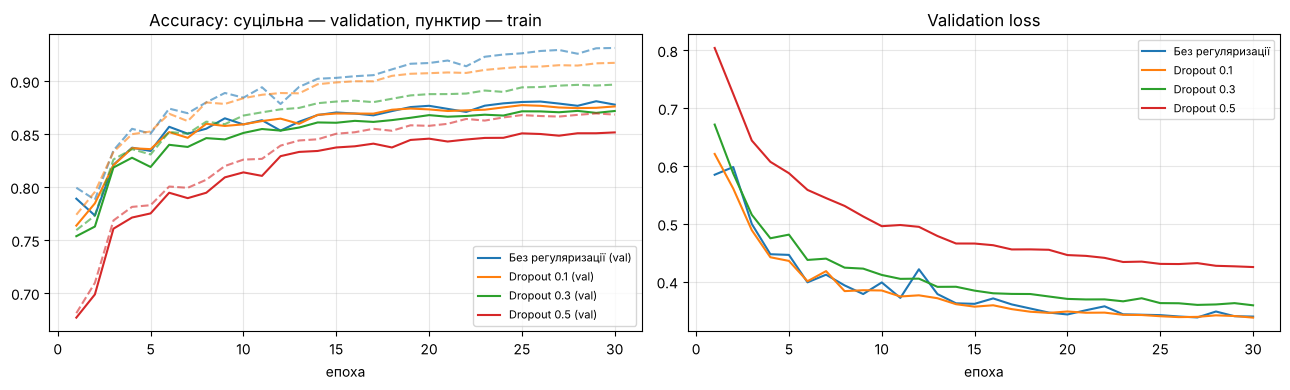

In [13]:
for p in [0.1, 0.2, 0.3, 0.5]:
    run_experiment(f'Dropout {p}', f'p = {p}', dropout=p)
DR_NAMES = ['Dropout 0.1', 'Dropout 0.3', 'Dropout 0.5']
show(['Без регуляризації'] + DR_NAMES + ['Dropout 0.2'])
for n in ['Без регуляризації'] + DR_NAMES:
    r = RESULTS[n]; print(f"{n:18s} розрив train−val accuracy = {r['Train acc'] - r['Val. accuracy']:+.4f}")
plot_hists(DR_NAMES, 'Dropout', xlim=(-0.6, 0.6))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ep = np.arange(1, EPOCHS + 1)
for n in ['Без регуляризації'] + DR_NAMES:
    l, = ax[0].plot(ep, HISTS[n]['val_acc'], label=f'{n} (val)')
    ax[0].plot(ep, HISTS[n]['train_acc'], ls='--', color=l.get_color(), alpha=0.6)
    ax[1].plot(ep, HISTS[n]['val_loss'], label=n)
ax[0].set_title('Accuracy: суцільна — validation, пунктир — train'); ax[0].set_xlabel('епоха'); ax[0].legend(fontsize=8)
ax[1].set_title('Validation loss'); ax[1].set_xlabel('епоха'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Опис результату (Dropout).**
- **Validation accuracy:** p = 0.1 → 0.8760, p = 0.2 → 0.8719, p = 0.3 → 0.8717, p = 0.5 → **0.8515**. Жоден варіант не перевершив базову (0.8777).
- **Розрив train−val зменшується** зі зростанням p: 5.3 → 4.1 → 2.5 → 1.7 п.п. Dropout справді **бореться з перенавчанням**: модель менше «запам'ятовує» train.
- **Мертвих нейронів 0** в усіх варіантах. Під час навчання кожен нейрон іноді «підміняє» інших, і всі вони отримують градієнт, тож жоден не «вмирає». (Діагностика зроблена з вимкненим Dropout, тому тимчасово вимкнені нейрони не рахуються мертвими.)
- **Sparsity не змінюється** (≈14.1%), і **гістограми ваг практично збігаються з базовою**: Dropout діє на активації, а не на ваги, тому розподіл ваг майже не змінюється.

**Криві навчання:** пунктирні лінії (train) зі збільшенням p опускаються ближче до суцільних (validation). При p = 0.5 навіть validation loss помітно вищий (0.425): модель стає надто обмеженою.

**Чому більший p не обов'язково кращий.** Наша мережа перенавчається лише помірно (розрив 5 п.п.), а при p = 0.5 на кожному кроці вимикається половина нейронів: мережа отримує дуже зашумлений сигнал і за 30 епох просто не встигає навчитися. Знижується і train, і validation accuracy, тобто з'являється **недонавчання**.

## 2.6 Weight clipping

Після **кожного** кроку оновлення ваги обрізаються до діапазону: W ← clip(W, −c, c). За умовою c = 1. Але після He-ініціалізації ваги дуже малі (std ≈ 0.05 для першого шару), тому заздалегідь зрозуміло, що межа ±1 може взагалі не спрацювати. Щоб побачити, **як жорстке обмеження впливає на навчання**, додатково пробуємо жорсткіші межі **c = 0.1** і **c = 0.05**.

Рахуємо, скільки ваг досягли меж ±c, і дивимось, чи з'являються «піки» біля меж на гістограмах.

,Параметри,"Dead neurons, %",dead L1,dead L2,dead L3,"Sparsity, %",Train acc,Val. accuracy,Val. loss,max|W|,ваг на межі ±c,"ваг на межі, %"
Метод,,,,,,,,,,,,
Без регуляризації,—,0.2232,0,0,1,14.0088,0.9312,0.8777,0.3395,0.8069,NaN,NaN
Weight clip ±1,c = 1,0.2232,0,0,1,14.0088,0.9312,0.8777,0.3395,0.8069,0.0,0.0000
Weight clip ±0.1,c = 0.1,0.2232,0,1,0,13.9556,0.8736,0.8570,0.4072,0.1000,1715.0,0.7078
Weight clip ±0.05,c = 0.05,2.9018,0,7,6,13.9886,0.7976,0.7945,0.5941,0.0500,9810.0,4.0486


max|W| по шарах у базовій моделі: [0.254, 0.407, 0.561, 0.807]
Weight clip ±1: ваг на межі по шарах: [0, 0, 0, 0]
Weight clip ±0.1: ваг на межі по шарах: [531, 710, 410, 64]
Weight clip ±0.05: ваг на межі по шарах: [6226, 2394, 1033, 157]


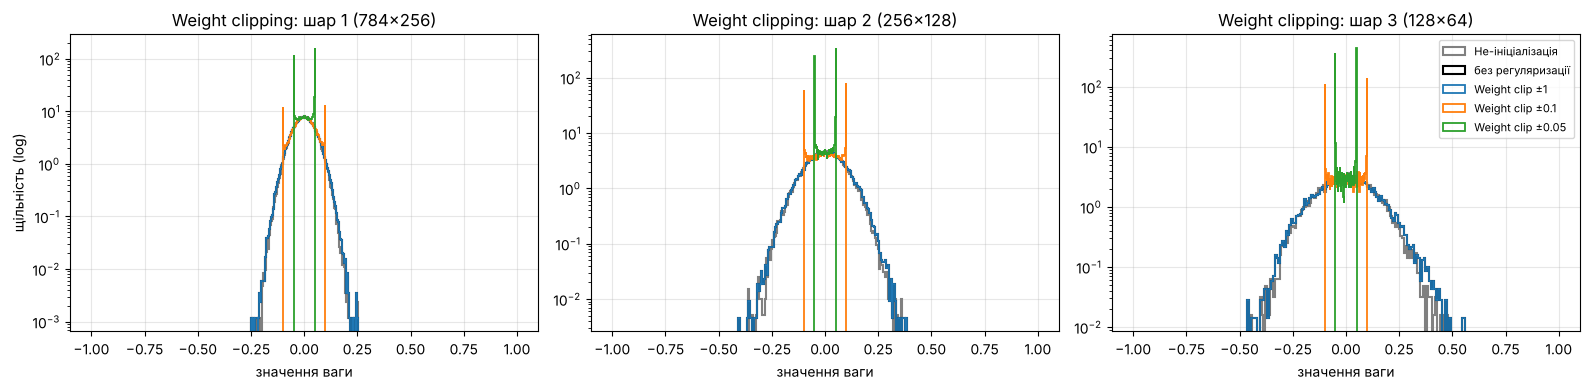

In [14]:
for c in [1.0, 0.1, 0.05]:
    run_experiment(f'Weight clip ±{c:g}', f'c = {c:g}', wclip=c)
WC_NAMES = [n for n in RESULTS if n.startswith('Weight clip')]
show(['Без регуляризації'] + WC_NAMES, cols=('Параметри', 'Dead neurons, %', 'dead L1', 'dead L2', 'dead L3', 'Sparsity, %',
                                             'Train acc', 'Val. accuracy', 'Val. loss', 'max|W|', 'ваг на межі ±c', 'ваг на межі, %'))
print('max|W| по шарах у базовій моделі:', [round(float(np.abs(W).max()), 3) for W in base_net.weights])
for n in WC_NAMES:
    c = float(n.split('±')[1])
    print(f"{n}: ваг на межі по шарах:", [int(np.sum(np.abs(W) >= c - 1e-7)) for W in NETS[n].weights])
plot_hists(WC_NAMES, 'Weight clipping', xlim=(-1.1, 1.1))

**Опис результату (weight clipping).**
- **c = 1 (за умовою):** результат **повністю збігається з базовою моделлю** (accuracy 0.8777, ті самі мертві нейрони). Жодна вага не досягла межі, бо найбільша вага навіть без обмеження лише 0.81 (а в прихованих шарах ≤ 0.56). Межа ±1 для такої мережі просто «не спрацьовує».
- **c = 0.1:** межі досягли **1715 ваг (0.7%)**, найбільше у шарах 1–2. Accuracy впала до **0.8570**, train до 0.874: модель уже не може зробити потрібні ваги великими.
- **c = 0.05:** межі досягли **9810 ваг (4%)**, accuracy лише **0.7945** (найгірший результат усієї роботи), з'явилось 13 мертвих нейронів.
- **Sparsity не змінюється** (≈14%): обрізання стосується великих ваг, а не малих.

**Гістограми:** для c = 0.1 і 0.05 видно **вертикальні «стіни» і гострі піки біля меж ±c**: усі ваги, які «хотіли» бути більшими, зібрались на межі. Для c = 1 розподіл ідентичний базовому.

**Як жорстке обмеження впливає на пошук оптимальних ваг:** якщо для найкращого розв'язку вага повинна бути, наприклад, 0.3, а межа 0.1, то модель ніколи не зможе її досягти. Градієнт штовхає вагу за межу, а clipping повертає її назад, тож багато ваг «застрягає» на межі. Модель втрачає здатність виражати сильні зв'язки і недонавчається. Причому це не штраф у функції втрат, а «стеля», тож модель навіть не знає про обмеження при обчисленні градієнта.

## 2.7 Gradient clipping

Тут обмежуються не ваги, а **градієнти**: якщо глобальна L2-норма всіх градієнтів ‖g‖ більша за поріг c, усі градієнти множаться на c/‖g‖ (напрямок кроку той самий, лише коротший). Щоб вибрати пороги, подивимось на типову норму градієнта в базовій моделі, а потім пробуємо **c ∈ {0.5, 1, 2}**.

Порівнюємо також **стабільність функції втрат**: наскільки сильно «стрибає» loss від батча до батча (стандартне відхилення втрат на батчах у перших епохах) і як виглядає крива втрат на тренувальних батчах.

Медіанна норма градієнта по епохах у базовій моделі: епоха 1 = 2.347, далі від 1.819 до 2.126


,Параметри,"Dead neurons, %",dead L1,dead L2,dead L3,"Sparsity, %",Train acc,Val. accuracy,Val. loss,"частка обрізаних кроків, %"
Метод,,,,,,,,,,
Без регуляризації,—,0.2232,0,0,1,14.0088,0.9312,0.8777,0.3395,NaN
Grad clip c=0.5,c = 0.5,0.8929,0,0,4,14.3056,0.8725,0.8558,0.4132,100.0000
Grad clip c=1,c = 1,0.6696,0,0,3,14.3002,0.8931,0.8651,0.3761,99.9255
Grad clip c=2,c = 2,0.6696,0,0,3,14.1318,0.9248,0.8741,0.3448,57.6145


Стабільність навчання:


,std втрат на батчах (епохи 1–3),std різниць сусідніх батчів (епохи 1–3),середня втрата (епоха 1),max втрата після 1-ї епохи
Метод,,,,
Без регуляризації,0.2508,0.1516,0.7808,0.9146
Grad clip c=0.5,0.3272,0.1405,1.0395,0.9652
Grad clip c=1,0.2793,0.1544,0.8781,0.9618
Grad clip c=2,0.2496,0.1662,0.7925,0.9599


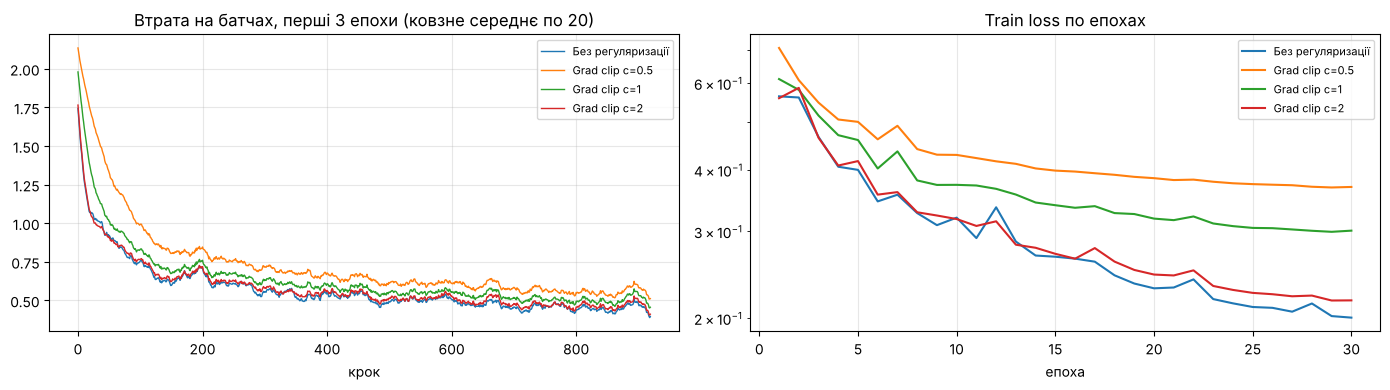

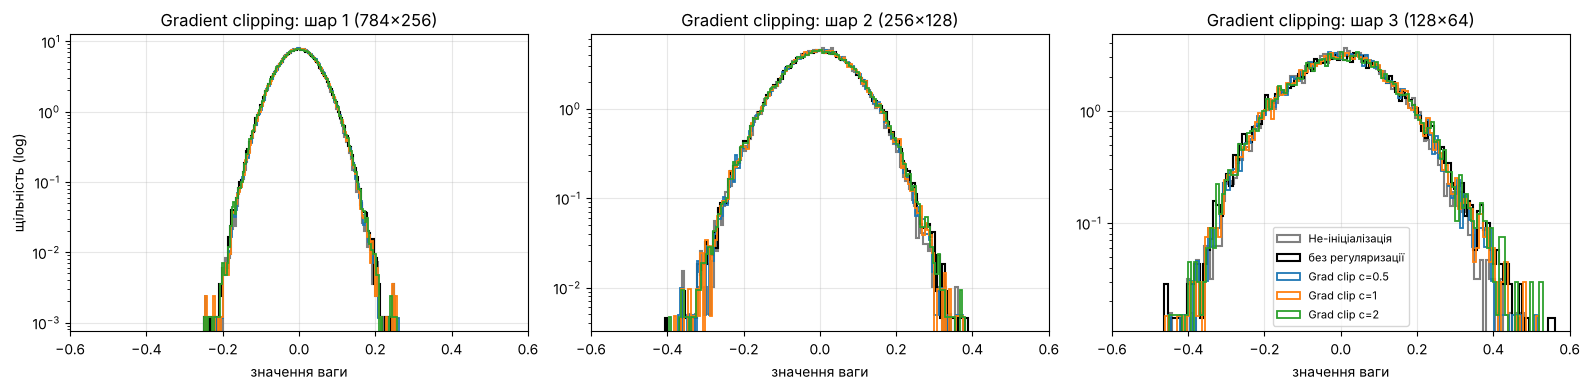

In [15]:
gn = np.array(HISTS['Без регуляризації']['grad_norm'])
print(f'Медіанна норма градієнта по епохах у базовій моделі: епоха 1 = {gn[0]:.3f}, далі від {gn[1:].min():.3f} до {gn[1:].max():.3f}')
for c in [0.5, 1.0, 2.0]:
    run_experiment(f'Grad clip c={c:g}', f'c = {c:g}', gclip=c)
GC_NAMES = [n for n in RESULTS if n.startswith('Grad clip')]
show(['Без регуляризації'] + GC_NAMES, cols=('Параметри', 'Dead neurons, %', 'dead L1', 'dead L2', 'dead L3', 'Sparsity, %',
                                             'Train acc', 'Val. accuracy', 'Val. loss', 'частка обрізаних кроків, %'))

steps_per_epoch = int(np.ceil(len(X_train) / BATCH))
rows = []
for n in ['Без регуляризації'] + GC_NAMES:
    bl = np.array(HISTS[n]['batch_loss'])
    rows.append({'Метод': n, 'std втрат на батчах (епохи 1–3)': bl[:3 * steps_per_epoch].std(),
                 'std різниць сусідніх батчів (епохи 1–3)': np.diff(bl[:3 * steps_per_epoch]).std(),
                 'середня втрата (епоха 1)': bl[:steps_per_epoch].mean(),
                 'max втрата після 1-ї епохи': bl[steps_per_epoch:].max()})
print('Стабільність навчання:')
display(pd.DataFrame(rows).set_index('Метод').round(4))

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
k = 20
for n in ['Без регуляризації'] + GC_NAMES:
    bl = np.array(HISTS[n]['batch_loss'])[:3 * steps_per_epoch]
    ax[0].plot(np.convolve(bl, np.ones(k) / k, mode='valid'), label=n, lw=1)
    ax[1].plot(np.arange(1, EPOCHS + 1), HISTS[n]['train_loss'], label=n)
ax[0].set_title('Втрата на батчах, перші 3 епохи (ковзне середнє по 20)'); ax[0].set_xlabel('крок'); ax[0].legend(fontsize=8)
ax[1].set_title('Train loss по епохах'); ax[1].set_xlabel('епоха'); ax[1].set_yscale('log'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
plot_hists(GC_NAMES, 'Gradient clipping', xlim=(-0.6, 0.6))

**Опис результату (gradient clipping).**
- **Типова норма градієнта** в базовій моделі — **≈1.8–2.3**. Тому пороги c = 0.5 і c = 1 обрізали майже **кожен крок** (100% і 99.9% кроків), а c = 2 — 58% кроків.
- **Якість:** c = 2 → **0.8741** (майже як базова), c = 1 → 0.8651, c = 0.5 → **0.8558**. Що менший поріг, то повільніше навчання: train accuracy теж нижча (0.925 / 0.893 / 0.873). Коли обрізається кожен крок, gradient clipping фактично **зменшує швидкість навчання**, і за 30 епох модель не встигає досягти того ж рівня.
- **Стабільність втрат:** у базовій моделі навчання і так стабільне, градієнти не «вибухають» (втрата після 1-ї епохи ніде не перевищує ≈0.91). Тому clipping не дає помітного виграшу в стабільності: розкид змін втрат між сусідніми батчами майже однаковий (0.14–0.17), а при c = 0.5 і 1 втрата просто спадає повільніше (лівий графік: помаранчева і зелена лінії вище). На правому графіку train loss при малих c плавніший, але вищий.
- **Мертві нейрони:** 3–4 у третьому шарі, sparsity ≈14%, розподіли ваг майже як базовий.

**Відмінність від weight clipping:** gradient clipping обмежує **розмір кроку**, а не самі ваги. Вага може стати будь-якою, просто рухатиметься до неї повільніше. Тому піків біля меж на гістограмах немає, і розподіл ваг майже не змінюється. Gradient clipping корисний, коли градієнти справді «вибухають» (глибокі чи рекурентні мережі, великий learning rate), а тут такої проблеми немає.

## 2.8 Комбінована регуляризація: L2 + Dropout 0.2

Обов'язкова комбінація з умови: **L2 (λ₂ = 10⁻³)** разом із **Dropout p = 0.2**. Порівнюємо з окремими експериментами **L2 λ = 10⁻³** і **Dropout 0.2** (ті самі параметри, але кожен метод окремо), а також з базовою моделлю. Чи краще разом, ніж окремо (**синергія**)? Чи, навпаки, разом вони занадто сильно обмежують модель?

,Параметри,"Dead neurons, %",dead L1,dead L2,dead L3,"Sparsity, %",Train acc,Val. accuracy,Val. loss
Метод,,,,,,,,,
Без регуляризації,—,0.2232,0,0,1,14.0088,0.9312,0.8777,0.3395
L2 λ=0.001,λ2 = 0.001,0.4464,0,0,2,16.9172,0.9198,0.8750,0.3369
Dropout 0.2,p = 0.2,0.0000,0,0,0,14.0373,0.9058,0.8719,0.3488
L2 + Dropout 0.2,"λ2 = 0.001, p = 0.2",0.0000,0,0,0,16.9576,0.9026,0.8704,0.3485


Без регуляризації  розрив train−val = +0.0534, val loss = 0.3395
L2 λ=0.001         розрив train−val = +0.0448, val loss = 0.3369
Dropout 0.2        розрив train−val = +0.0339, val loss = 0.3488
L2 + Dropout 0.2   розрив train−val = +0.0322, val loss = 0.3485


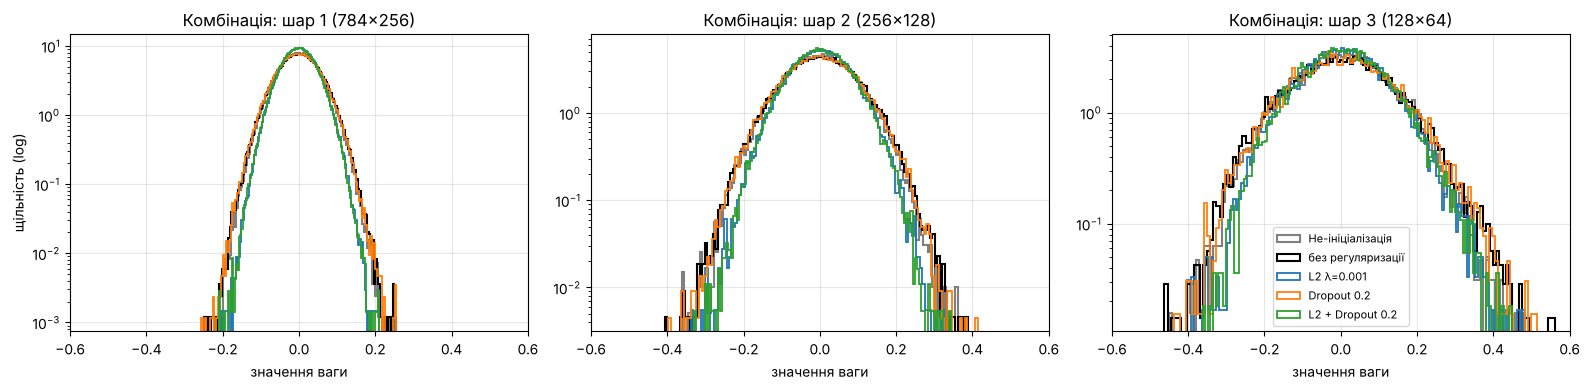

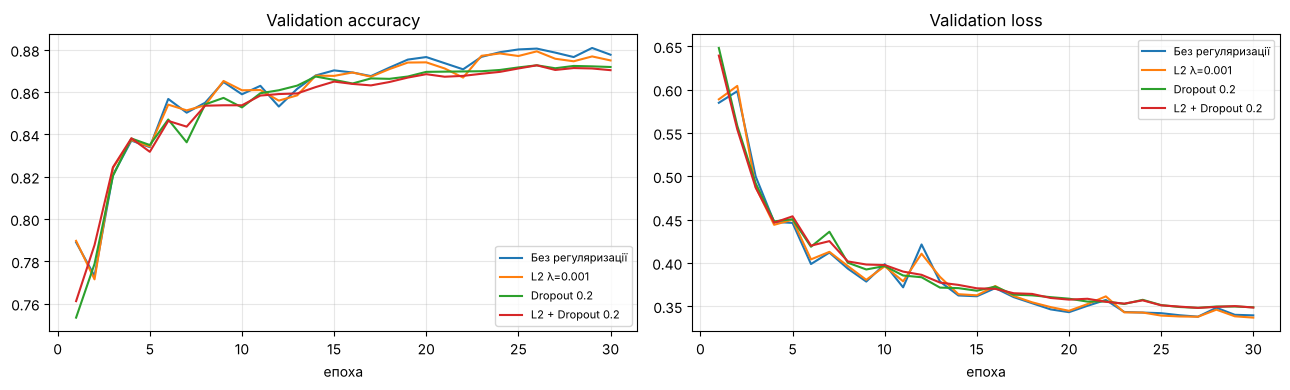

In [16]:
run_experiment('L2 + Dropout 0.2', 'λ2 = 0.001, p = 0.2', l2=1e-3, dropout=0.2)
CMB = ['Без регуляризації', 'L2 λ=0.001', 'Dropout 0.2', 'L2 + Dropout 0.2']
show(CMB)
for n in CMB:
    r = RESULTS[n]; print(f"{n:18s} розрив train−val = {r['Train acc'] - r['Val. accuracy']:+.4f}, val loss = {r['Val. loss']:.4f}")
plot_hists(['L2 λ=0.001', 'Dropout 0.2', 'L2 + Dropout 0.2'], 'Комбінація', xlim=(-0.6, 0.6))
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for n in CMB:
    ax[0].plot(np.arange(1, EPOCHS + 1), HISTS[n]['val_acc'], label=n)
    ax[1].plot(np.arange(1, EPOCHS + 1), HISTS[n]['val_loss'], label=n)
ax[0].set_title('Validation accuracy'); ax[1].set_title('Validation loss')
for a in ax: a.set_xlabel('епоха'); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Опис результату (L2 + Dropout 0.2).**

| Метод | Val. accuracy | Val. loss | Розрив train−val | Мертві | Sparsity |
|---|---|---|---|---|---|
| Без регуляризації | 0.8777 | 0.3395 | 5.3 п.п. | 1 | 14.0% |
| L2 λ=10⁻³ | **0.8750** | **0.3369** | 4.5 п.п. | 2 | 16.9% |
| Dropout 0.2 | 0.8719 | 0.3488 | 3.4 п.п. | 0 | 14.0% |
| L2 + Dropout 0.2 | 0.8704 | 0.3485 | **3.2 п.п.** | **0** | 17.0% |

- **Точність не покращилася:** комбінація (0.8704) трохи гірша за кожен метод окремо й за базову модель.
- **Мертві нейрони:** 0, як і в Dropout (L2 сам по собі дав 2). Тут Dropout «вирішує» цю проблему.
- **Sparsity:** 17.0%, як у L2 (16.9%): частку малих ваг визначає саме L2, Dropout на неї не впливає. Гістограми комбінації майже збігаються з L2.
- **Розрив train−val найменший** (3.2 п.п.): перенавчання найслабше, але за рахунок того, що train accuracy теж знизилась.

**Висновок:** **синергії немає**. Методи складаються як «два обмеження», а не підсилюють одне одного: для нашої помірно перенавченої мережі разом вони вже трохи **надмірно обмежують** модель. Комбінація могла б допомогти, якби модель сильно перенавчалась (більша мережа, менше даних, довше навчання).

# Аналіз і порівняння результатів

## 3.1 Порівняльна таблиця

Усі експерименти в одній таблиці (форма з розділу 4.1 умови). Для методів із коефіцієнтами вказано використані λ₁, λ₂, p і пороги clipping. Для зручності окремо виділено «представників» кожного методу (середні значення коефіцієнтів), а нижче — повна таблиця.

In [17]:
ORDER = (['Без регуляризації'] + L1_NAMES + L2_NAMES + DR_NAMES + ['Dropout 0.2'] + WC_NAMES + GC_NAMES + ['L2 + Dropout 0.2'])
full = pd.DataFrame([RESULTS[n] for n in ORDER]).set_index('Метод')
main_rows = ['Без регуляризації', 'L1 λ=0.0001', 'L2 λ=0.001', 'Dropout 0.1', 'Dropout 0.3', 'Dropout 0.5',
             'Weight clip ±1', 'Grad clip c=1', 'L2 + Dropout 0.2']
print('Таблиця 4.1 (основні варіанти)')
display(full.loc[main_rows, ['Параметри', 'Dead neurons, %', 'Sparsity, %', 'Val. accuracy', 'Val. loss']].round(4))
print('Повна таблиця всіх експериментів')
display(full[['Параметри', 'Dead neurons, %', 'dead L1', 'dead L2', 'dead L3', 'Sparsity, %', 'Train acc', 'Val. accuracy', 'Val. loss']].round(4))
print('Найкраща val accuracy:', full['Val. accuracy'].idxmax(), round(full['Val. accuracy'].max(), 4),
      '| найменша val loss:', full['Val. loss'].idxmin(), round(full['Val. loss'].min(), 4))

Таблиця 4.1 (основні варіанти)


,Параметри,"Dead neurons, %","Sparsity, %",Val. accuracy,Val. loss
Метод,,,,,
Без регуляризації,—,0.2232,14.0088,0.8777,0.3395
L1 λ=0.0001,λ1 = 0.0001,0.4464,39.3114,0.8757,0.3370
L2 λ=0.001,λ2 = 0.001,0.4464,16.9172,0.8750,0.3369
Dropout 0.1,p = 0.1,0.0000,14.0683,0.8760,0.3377
Dropout 0.3,p = 0.3,0.0000,14.0980,0.8717,0.3590
Dropout 0.5,p = 0.5,0.0000,14.1488,0.8515,0.4251
Weight clip ±1,c = 1,0.2232,14.0088,0.8777,0.3395
Grad clip c=1,c = 1,0.6696,14.3002,0.8651,0.3761
L2 + Dropout 0.2,"λ2 = 0.001, p = 0.2",0.0000,16.9576,0.8704,0.3485


Повна таблиця всіх експериментів


,Параметри,"Dead neurons, %",dead L1,dead L2,dead L3,"Sparsity, %",Train acc,Val. accuracy,Val. loss
Метод,,,,,,,,,
Без регуляризації,—,0.2232,0,0,1,14.0088,0.9312,0.8777,0.3395
L1 λ=1e-05,λ1 = 1e-05,0.2232,0,0,1,16.5036,0.9320,0.8793,0.3350
L1 λ=0.0001,λ1 = 0.0001,0.4464,0,0,2,39.3114,0.9176,0.8757,0.3370
L1 λ=0.001,λ1 = 0.001,13.6161,38,15,8,97.6294,0.8435,0.8335,0.4753
L2 λ=0.0001,λ2 = 0.0001,0.4464,0,0,2,14.2697,0.9308,0.8780,0.3371
L2 λ=0.001,λ2 = 0.001,0.4464,0,0,2,16.9172,0.9198,0.8750,0.3369
L2 λ=0.01,λ2 = 0.01,3.1250,0,6,8,62.9771,0.8670,0.8523,0.4320
Dropout 0.1,p = 0.1,0.0000,0,0,0,14.0683,0.9171,0.8760,0.3377
Dropout 0.3,p = 0.3,0.0000,0,0,0,14.0980,0.8966,0.8717,0.3590


Найкраща val accuracy: L1 λ=1e-05 0.8793 | найменша val loss: L1 λ=1e-05 0.335


**Опис результату (порівняльна таблиця).**
- **Найкраща validation accuracy і найменша validation loss** в **L1 λ = 10⁻⁵** (0.8793 і 0.3350), але це лише на 0.16 п.п. краще за базову модель (0.8777). Практично всі «слабкі» варіанти (L1 10⁻⁵…10⁻⁴, L2 10⁻⁴…10⁻³, Dropout 0.1, weight clip ±1, grad clip 2) дають **0.874–0.879**: різниця між ними менша за 0.5 п.п., тобто в межах шуму.
- **Сильні варіанти помітно гірші:** L1 10⁻³ (0.834), weight clip ±0.05 (0.795), Dropout 0.5 (0.852), L2 10⁻² (0.852), grad clip 0.5 (0.856).
- **Мертві нейрони** з'являються у великій кількості лише при надмірній регуляризації: L1 10⁻³ (13.6%), L2 10⁻² (3.1%), weight clip ±0.05 (2.9%). У Dropout і комбінації їх **0**.
- **Sparsity** змінюють лише L1 (до 97.6%) і L2 (до 63%); решта методів лишає її на рівні ініціалізації ≈14%.

## 3.2 Мертві нейрони по шарах і sparsity по матрицях

Таблиця мертвих нейронів для кожного прихованого шару в кожному експерименті (кількість і частка) та розрідженість кожної матриці ваг.

Мертві нейрони по шарах


,dead L1,dead L2,dead L3,"L1, % (з 256)","L2, % (з 128)","L3, % (з 64)",усього мертвих
Метод,,,,,,,
Без регуляризації,0,0,1,0.00,0.00,1.56,1
L1 λ=1e-05,0,0,1,0.00,0.00,1.56,1
L1 λ=0.0001,0,0,2,0.00,0.00,3.12,2
L1 λ=0.001,38,15,8,14.84,11.72,12.50,61
L2 λ=0.0001,0,0,2,0.00,0.00,3.12,2
L2 λ=0.001,0,0,2,0.00,0.00,3.12,2
L2 λ=0.01,0,6,8,0.00,4.69,12.50,14
Dropout 0.1,0,0,0,0.00,0.00,0.00,0
Dropout 0.3,0,0,0,0.00,0.00,0.00,0


Sparsity (|w| < 0.01) по матрицях ваг, %


,"sparsity W1, %","sparsity W2, %","sparsity W3, %","sparsity W4, %","Sparsity, %"
Метод,,,,,
Без регуляризації,15.22,8.84,5.96,3.12,14.01
L1 λ=1e-05,17.97,10.27,6.64,2.81,16.50
L1 λ=0.0001,42.71,24.80,16.63,6.41,39.31
L1 λ=0.001,98.82,95.12,82.10,52.50,97.63
L2 λ=0.0001,15.52,8.94,5.91,2.97,14.27
L2 λ=0.001,18.41,10.51,6.96,3.12,16.92
L2 λ=0.01,68.21,40.65,28.12,11.09,62.98
Dropout 0.1,15.32,8.67,5.87,2.66,14.07
Dropout 0.3,15.27,9.10,6.23,2.34,14.10


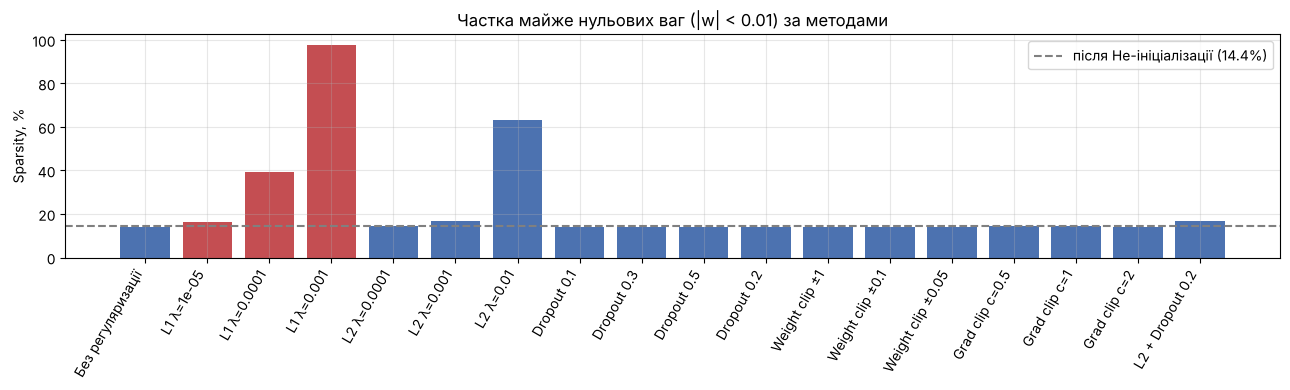

In [18]:
dt = full[['dead L1', 'dead L2', 'dead L3']].copy()
for i, n in enumerate(HIDDEN, 1):
    dt[f'L{i}, % (з {n})'] = 100 * dt[f'dead L{i}'] / n
dt['усього мертвих'] = full[['dead L1', 'dead L2', 'dead L3']].sum(1)
print('Мертві нейрони по шарах')
display(dt.round(2))
print('Sparsity (|w| < 0.01) по матрицях ваг, %')
display(full[[c for c in full.columns if c.startswith('sparsity W')] + ['Sparsity, %']].round(2))

fig, ax = plt.subplots(figsize=(13, 4))
x = np.arange(len(ORDER))
ax.bar(x, full['Sparsity, %'], color=['#C44E52' if n.startswith('L1') else '#4C72B0' for n in ORDER])
ax.axhline(sparsity(W_init), color='gray', ls='--', label=f'після He-ініціалізації ({sparsity(W_init):.1f}%)')
ax.set_xticks(x); ax.set_xticklabels(ORDER, rotation=60, ha='right'); ax.set_ylabel('Sparsity, %')
ax.set_title('Частка майже нульових ваг (|w| < 0.01) за методами'); ax.legend(); plt.tight_layout(); plt.show()

**Опис результату.**
- **Мертві нейрони по шарах:** у більшості експериментів мертвих нейронів 0–4, і майже всі вони в **третьому шарі** (64 нейрони); у другому шарі мертві нейрони з'являються лише при сильних обмеженнях (L2 10⁻², weight clip ±0.05/±0.1, L1 10⁻³). Перший шар (256 нейронів) втрачає нейрони лише при **L1 λ = 10⁻³** (38 нейронів, 14.8%). Пояснення: L1 обнуляє майже всі вхідні ваги нейрона, і тоді його передактивація залежить лише від зміщення; якщо зміщення від'ємне, нейрон «вимикається» назавжди.
- **Sparsity по матрицях:** найбільша частка малих ваг завжди в першому шарі (у базовій 15.2%, бо там найменша std при ініціалізації). L1 10⁻³ майже повністю «спустошує» шари 1–2 (98.8% і 95.1% малих ваг), а вихідний шар 64×10 найменш розріджений.
- **Стовпчиковий графік:** червоні стовпчики (L1) і L2 10⁻² — єдині, що помітно виходять за рівень ініціалізації (сіра пунктирна лінія ≈14.4%). Dropout, clipping та комбінація цієї лінії майже не перетинають.

## 3.3 Розподіл ваг: усі методи разом

Для кожного методу — розподіл ваг **усіх прихованих шарів разом** (W1, W2, W3) у порівнянні з початковим розподілом (He) і базовою моделлю. Логарифмічна шкала по вертикалі, щоб було видно і «хвости», і пік біля нуля.

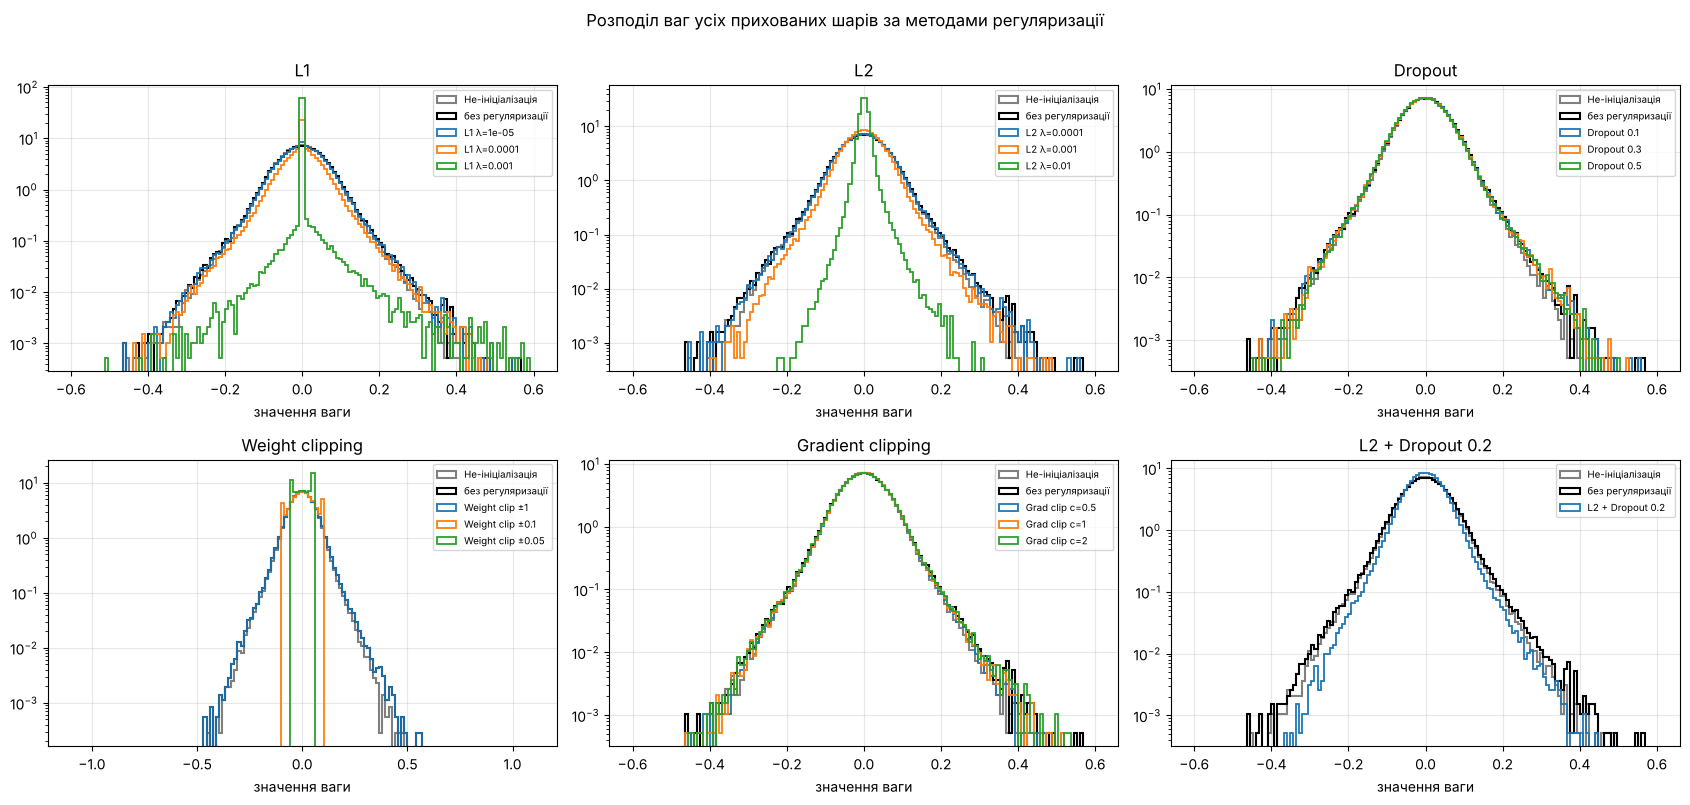

,std ваг (приховані),"частка |w|<0.01, %","частка |w|<0.001, %",max|w|
Без регуляризації,0.0634,14.0377,1.4433,0.5610
L1 λ=1e-05,0.0619,16.5399,2.6781,0.5554
L1 λ=0.0001,0.0503,39.3985,26.1562,0.5468
L1 λ=0.001,0.0150,97.7489,97.1402,0.8609
L2 λ=0.0001,0.0622,14.2996,1.4537,0.5572
L2 λ=0.001,0.0527,16.9537,1.6891,0.4832
L2 λ=0.01,0.0156,63.1145,7.4943,0.3067
Dropout 0.1,0.0631,14.0985,1.4628,0.5558
Dropout 0.3,0.0629,14.1291,1.4243,0.5250
Dropout 0.5,0.0625,14.1796,1.4545,0.4961


In [19]:
groups = [('L1', L1_NAMES), ('L2', L2_NAMES), ('Dropout', DR_NAMES), ('Weight clipping', WC_NAMES),
          ('Gradient clipping', GC_NAMES), ('L2 + Dropout 0.2', ['L2 + Dropout 0.2'])]
fig, axes = plt.subplots(2, 3, figsize=(17, 8))
w_init_all = np.concatenate([W.ravel() for W in W_init[:3]])
w_base_all = np.concatenate([W.ravel() for W in hidden_w(base_net)])
for ax, (title, names) in zip(axes.ravel(), groups):
    rng_ = (-1.1, 1.1) if title == 'Weight clipping' else (-0.6, 0.6)
    ax.hist(w_init_all, bins=150, range=rng_, histtype='step', color='gray', lw=1.5, density=True, label='He-ініціалізація')
    ax.hist(w_base_all, bins=150, range=rng_, histtype='step', color='black', lw=1.5, density=True, label='без регуляризації')
    for n in names:
        ax.hist(np.concatenate([W.ravel() for W in hidden_w(NETS[n])]), bins=150, range=rng_, histtype='step', lw=1.3, density=True, label=n)
    ax.set_yscale('log'); ax.set_title(title); ax.set_xlabel('значення ваги'); ax.legend(fontsize=7)
plt.suptitle('Розподіл ваг усіх прихованих шарів за методами регуляризації', y=1.0); plt.tight_layout(); plt.show()

stat = pd.DataFrame({n: {'std ваг (приховані)': float(np.concatenate([W.ravel() for W in hidden_w(NETS[n])]).std()),
                         'частка |w|<0.01, %': sparsity(hidden_w(NETS[n])),
                         'частка |w|<0.001, %': sparsity(hidden_w(NETS[n]), 0.001),
                         'max|w|': float(max(np.abs(W).max() for W in hidden_w(NETS[n])))} for n in ORDER}).T
stat.loc['He-ініціалізація'] = [float(w_init_all.std()), sparsity(W_init[:3]), sparsity(W_init[:3], 0.001), float(np.abs(w_init_all).max())]
display(stat.round(4))

**Опис результату (розподіл ваг усіх прихованих шарів).**
- **L1:** гострий пік у нулі і «зрізані» плечі розподілу; при λ = 10⁻³ майже всі ваги в нулі, але є окремі великі ваги (до 0.86).
- **L2:** розподіл симетрично **звужується** (std з 0.063 до 0.016 при λ = 10⁻²), без окремого піку рівно в нулі: частка |w| < 0.001 лише 7.5% проти 97% у L1 10⁻³.
- **Dropout і gradient clipping:** криві майже накладаються на базову: ці методи майже не змінюють розподіл ваг.
- **Weight clipping:** для ±0.1 і ±0.05 розподіл обрізаний «стінами» з піками на межах; для ±1 він збігається з базовим. **Піків біля ±1 немає**, бо жодна вага до 1 не доростає.
- **L2 + Dropout:** схоже на L2 λ = 10⁻³, трохи вужче за базовий розподіл.

Таблиця під рисунком підтверджує це числами: std ваг, частка |w| < 0.01 і < 0.001, максимальна вага.

## 3.4 Мертві нейрони ↔ точність (діаграма розсіювання)

Кожна точка — окремий експеримент: по осі x частка мертвих нейронів (усі приховані шари разом), по y — validation accuracy. Праворуч та сама точність, але залежно від sparsity: це допоможе відповісти, чи є «баланс» між розрідженістю ваг і мертвими нейронами.

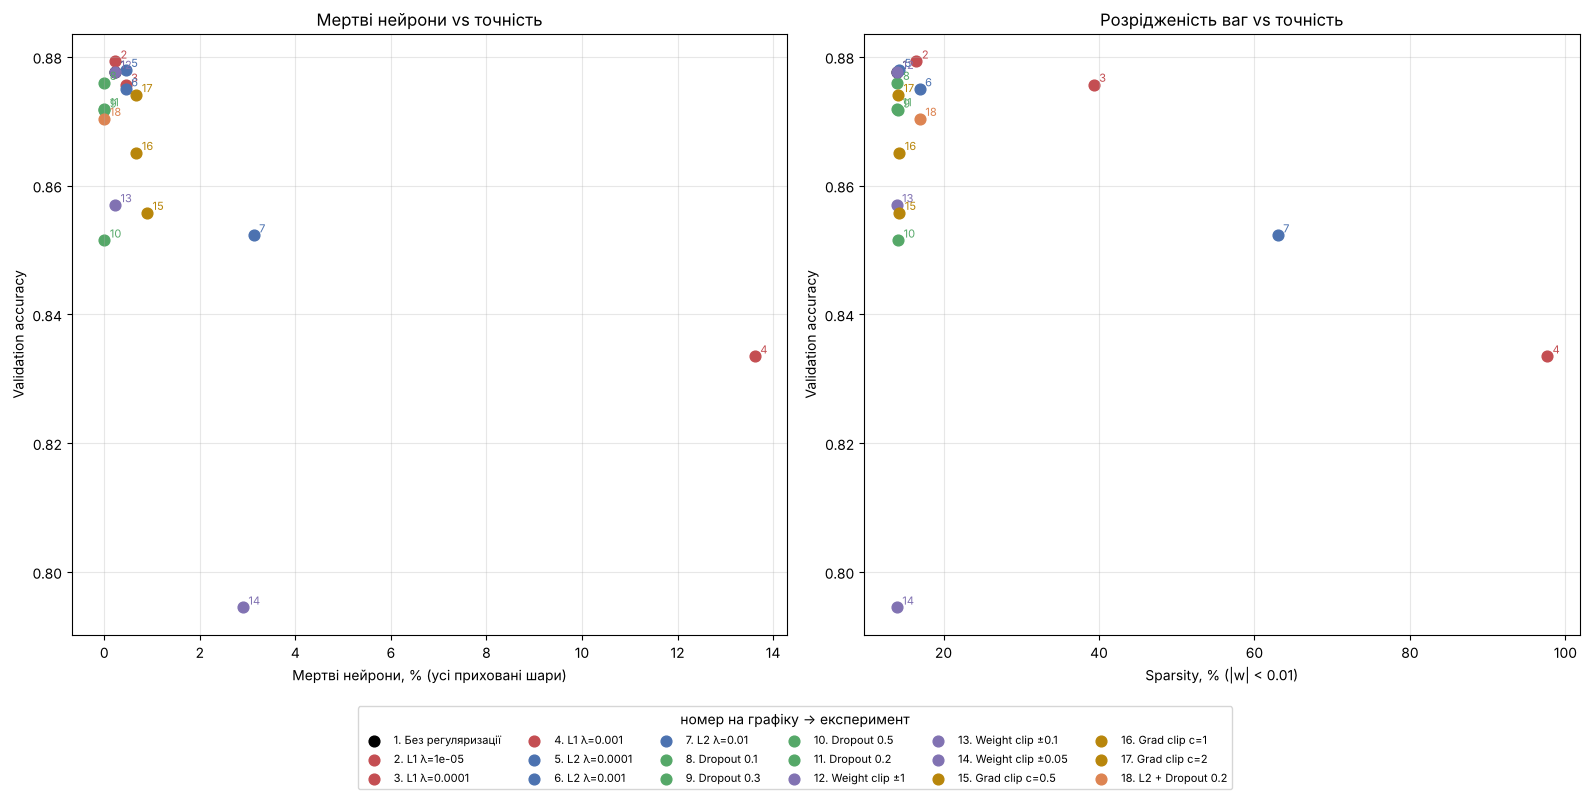

Кореляція Спірмена: dead vs accuracy = -0.379; sparsity vs accuracy = -0.114; dead vs sparsity = 0.380
Експериментів з 0 мертвих нейронів: 5; їхня val accuracy від 0.8515 до 0.8760


In [20]:
fig, ax = plt.subplots(1, 2, figsize=(16, 8))
def fam_color(n):
    if n.startswith('L2 +'): return '#DD8452'
    for pre, col in [('Без', 'black'), ('L1', '#C44E52'), ('L2', '#4C72B0'), ('Dropout', '#55A868'), ('Weight', '#8172B2'), ('Grad', '#B8860B')]:
        if n.startswith(pre): return col
    return 'gray'
for k, n in enumerate(ORDER, 1):
    r = RESULTS[n]; col = fam_color(n)
    for a, xk in zip(ax, ['Dead neurons, %', 'Sparsity, %']):
        a.scatter(r[xk], r['Val. accuracy'], s=60, color=col, label=f'{k}. {n}' if a is ax[0] else None)
        a.annotate(str(k), (r[xk], r['Val. accuracy']), fontsize=8, xytext=(4, 2), textcoords='offset points', color=col)
fig.legend(fontsize=8, loc='lower center', ncol=6, title='номер на графіку → експеримент', bbox_to_anchor=(0.5, 0.0))
ax[0].set_xlabel('Мертві нейрони, % (усі приховані шари)'); ax[0].set_ylabel('Validation accuracy')
ax[0].set_title('Мертві нейрони vs точність')
ax[1].set_xlabel('Sparsity, % (|w| < 0.01)'); ax[1].set_ylabel('Validation accuracy'); ax[1].set_title('Розрідженість ваг vs точність')
plt.tight_layout(rect=(0, 0.12, 1, 1)); plt.show()

d = full['Dead neurons, %']; s = full['Sparsity, %']; a = full['Val. accuracy']
print(f'Кореляція Спірмена: dead vs accuracy = {d.corr(a, method="spearman"):.3f}; sparsity vs accuracy = {s.corr(a, method="spearman"):.3f}; dead vs sparsity = {d.corr(s, method="spearman"):.3f}')
zero_dead = full[full['dead L1'] + full['dead L2'] + full['dead L3'] == 0]
print(f"Експериментів з 0 мертвих нейронів: {len(zero_dead)}; їхня val accuracy від {zero_dead['Val. accuracy'].min():.4f} до {zero_dead['Val. accuracy'].max():.4f}")

**Опис результату (діаграма «мертві нейрони ↔ точність»).** Числа біля точок відповідають номерам у легенді.

1. **Чи є залежність?** Слабка: кореляція Спірмена між часткою мертвих нейронів і accuracy **−0.38**. Більшість експериментів зібралися в лівому верхньому куті (0–1% мертвих, accuracy 0.85–0.88).
2. **Чи знижує точність велика кількість мертвих нейронів?** Найбільше мертвих (13.6%) у L1 10⁻³, і вона справді має низьку точність (0.834). Але **найгірша** модель (weight clip ±0.05, 0.795) має лише 2.9% мертвих, а L2 10⁻² з 3.1% мертвих має 0.852. Отже, точність знижує не сама кількість мертвих нейронів, а **надмірне обмеження моделі**, яке водночас «вбиває» частину нейронів.
3. **Чи можуть моделі з однаковою кількістю мертвих нейронів мати різну точність?** Так: **5 експериментів мають 0 мертвих нейронів**, але їхня accuracy від **0.8515** (Dropout 0.5) до **0.8760** (Dropout 0.1). Різниця 2.5 п.п. пояснюється силою регуляризації, а не мертвими нейронами.
4. **Чи є оптимальний баланс між sparsity і мертвими нейронами?** На правому графіку видно: можна мати багато малих ваг майже без втрат. **L1 λ = 10⁻⁴** — **39% майже нульових ваг**, лише 0.45% мертвих нейронів і точність 0.876 (на 0.2 п.п. гірше за базову). Це гарний баланс. Далі (L2 10⁻², 63%; L1 10⁻³, 98%) точність падає, і з'являються мертві нейрони. Кореляція між sparsity і мертвими нейронами помірна (**0.38**): велика кількість малих ваг не обов'язково означає мертві нейрони.

## 3.5 Сила регуляризації і якість: слабка проти сильної

Щоб відповісти на питання «чи завжди сильніша регуляризація краща», для L1, L2, Dropout і clipping показуємо, як змінюються **train accuracy**, **validation accuracy** і їх **розрив** (ознака перенавчання) зі збільшенням сили методу.

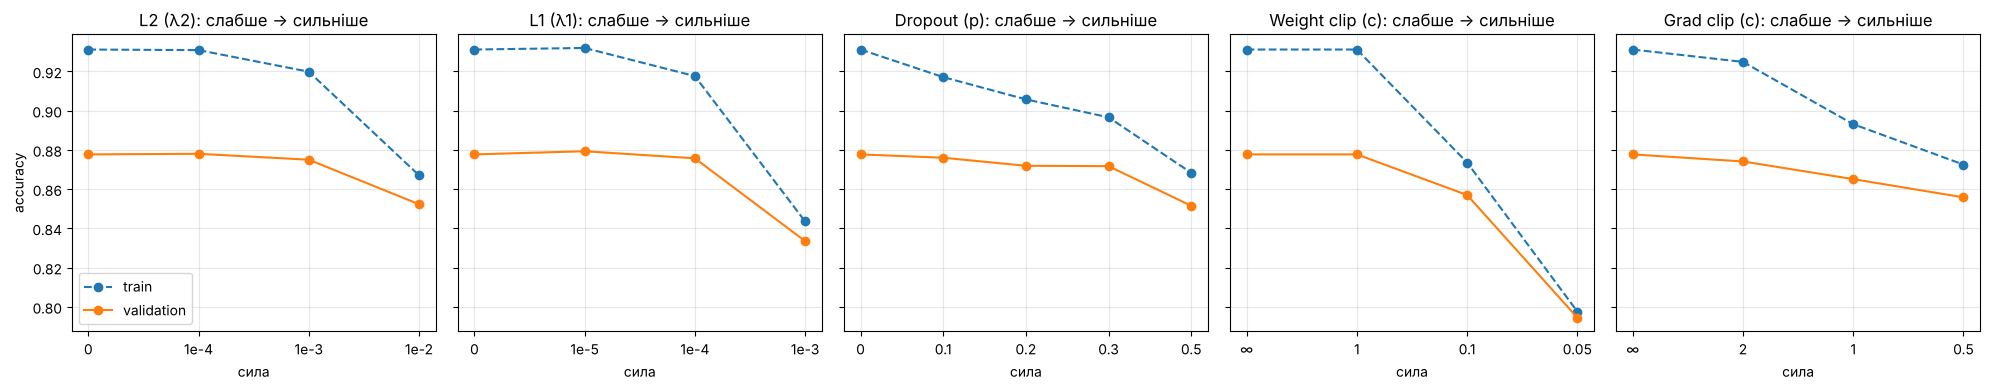

,Метод,сила,train acc,val acc,розрив train−val,val loss
0,L2 (λ2),0,0.9312,0.8777,0.0534,0.3395
1,L2 (λ2),1e-4,0.9308,0.8780,0.0528,0.3371
2,L2 (λ2),1e-3,0.9198,0.8750,0.0448,0.3369
3,L2 (λ2),1e-2,0.8670,0.8523,0.0148,0.4320
4,L1 (λ1),0,0.9312,0.8777,0.0534,0.3395
5,L1 (λ1),1e-5,0.9320,0.8793,0.0526,0.3350
6,L1 (λ1),1e-4,0.9176,0.8757,0.0419,0.3370
7,L1 (λ1),1e-3,0.8435,0.8335,0.0100,0.4753
8,Dropout (p),0,0.9312,0.8777,0.0534,0.3395
9,Dropout (p),0.1,0.9171,0.8760,0.0411,0.3377


In [21]:
fam = [('L2 (λ2)', ['Без регуляризації'] + L2_NAMES, ['0', '1e-4', '1e-3', '1e-2']),
       ('L1 (λ1)', ['Без регуляризації'] + L1_NAMES, ['0', '1e-5', '1e-4', '1e-3']),
       ('Dropout (p)', ['Без регуляризації', 'Dropout 0.1', 'Dropout 0.2', 'Dropout 0.3', 'Dropout 0.5'], ['0', '0.1', '0.2', '0.3', '0.5']),
       ('Weight clip (c)', ['Без регуляризації', 'Weight clip ±1', 'Weight clip ±0.1', 'Weight clip ±0.05'], ['∞', '1', '0.1', '0.05']),
       ('Grad clip (c)', ['Без регуляризації', 'Grad clip c=2', 'Grad clip c=1', 'Grad clip c=0.5'], ['∞', '2', '1', '0.5'])]
fig, axes = plt.subplots(1, 5, figsize=(20, 4), sharey=True)
for ax, (title, names, labels) in zip(axes, fam):
    tr = [RESULTS[n]['Train acc'] for n in names]; va = [RESULTS[n]['Val. accuracy'] for n in names]
    ax.plot(labels, tr, 'o--', label='train'); ax.plot(labels, va, 'o-', label='validation')
    ax.set_title(f'{title}: слабше → сильніше'); ax.set_xlabel('сила')
axes[0].set_ylabel('accuracy'); axes[0].legend(); plt.tight_layout(); plt.show()

rows = []
for title, names, labels in fam:
    for n, lab in zip(names, labels):
        r = RESULTS[n]
        rows.append({'Метод': title, 'сила': lab, 'train acc': r['Train acc'], 'val acc': r['Val. accuracy'],
                     'розрив train−val': r['Train acc'] - r['Val. accuracy'], 'val loss': r['Val. loss']})
display(pd.DataFrame(rows).round(4))

**Опис результату (сила регуляризації).** На кожному графіку зліва направо регуляризація посилюється; пунктир — train, суцільна — validation.
- **Train accuracy завжди падає** зі збільшенням сили: модель стає «простішою».
- **Розрив train−val завжди зменшується** (наприклад, L2: 5.3 → 1.5 п.п., Dropout: 5.3 → 1.7, weight clip ±0.05: 0.3 п.п.) — тобто перенавчання справді слабшає.
- Але **validation accuracy спершу майже не змінюється** (слабка регуляризація: ±0.2 п.п.), а **потім падає** (сильна): лінії train і validation сходяться не тому, що validation росте, а тому, що train падає. Це **недонавчання**.

Отже, **сильніша регуляризація не завжди краща**: вона корисна до певної межі, після якої модель втрачає здатність вивчити закономірності.

## 3.6 Дослідницьке питання: чи завжди сильніша регуляризація покращує узагальнення?

**Ні.** Наші експерименти показують однакову картину для всіх методів:
- **Слабка регуляризація** (L2 λ ≤ 10⁻³, L1 λ ≤ 10⁻⁴, Dropout 0.1, grad clip c = 2, weight clip ±1) **зменшує розрив** між train і validation (перенавчання слабшає), а validation accuracy лишається на рівні базової моделі (0.874–0.879) і іноді трохи кращою (L1 10⁻⁵ — 0.8793). Validation loss у L1/L2 трохи нижчий за базовий (0.335–0.337 проти 0.340).
- **Сильна регуляризація** (L2 10⁻², L1 10⁻³, Dropout 0.5, weight clip ±0.05, grad clip 0.5) **знижує і train, і validation accuracy** на 2–8 п.п. Це **недонавчання**: модель обмежена так сильно, що не може вивчити навіть тренувальні дані.

**Коли регуляризація допомагає, а коли шкодить.** Регуляризація зменшує перенавчання, коли модель **занадто гнучка для обсягу даних** (великий розрив train−val). У нашій мережі розрив помірний (5 п.п.), тому простору для покращення мало, і навіть оптимальна регуляризація дає лише ±0.2 п.п. Якби мережа була більшою, а даних менше (або навчання довшим), перевага регуляризації була б помітнішою. Коли ж розрив уже невеликий, додаткова регуляризація лише «забирає» корисну гнучкість моделі.

## 3.7 Різниця між поняттями

- **Мала величина ваг.** Ваги невеликі за модулем (наприклад, 0.02–0.1), але не нульові, тому кожна все одно впливає на результат. Це типовий ефект **L2**: усі ваги стають меншими, модель «спокійніша».
- **Нульова або майже нульова вага.** |w| < 0.01 (так ми рахували sparsity): зв'язок між двома нейронами фактично **відсутній**. Типовий ефект **L1**. Важливо: це властивість **окремого зв'язку**, а не нейрона. Нейрон може мати багато нульових ваг і бути цілком активним.
- **Неактивний нейрон.** Нейрон, вихід якого ReLU дорівнює 0 **для конкретного об'єкта** чи невеликої частки об'єктів. Це нормально: ReLU-нейрони і повинні вмикатися лише для частини входів (у базовій моделі більшість нейронів активні на 20–90% об'єктів). Також «неактивний» — нейрон, тимчасово вимкнений Dropout на одному кроці навчання.
- **Мертвий нейрон.** Нейрон, передактивація якого Z ≤ 0 **для всіх** об'єктів вибірки: він завжди видає 0, не передає сигнал далі й не отримує градієнта (похідна ReLU = 0), тож перестає навчатися. У нас їх небагато: 0–4 у звичайних експериментах і 61 при L1 λ = 10⁻³. Причому «мертвий на train» ще не означає мертвий для будь-якого можливого зображення.
- **Надмірно регуляризована модель.** Модель, у якій регуляризація настільки сильна, що вона **недонавчається**: низька train accuracy, мала різниця train−val, але й низька validation accuracy (L1 10⁻³: 0.844 / 0.834; weight clip ±0.05: 0.798 / 0.795). Часто має багато нульових ваг і/або мертвих нейронів, але головна ознака — погана якість навіть на тренувальних даних.

## Висновки

**Блок 1.** Повнозв'язну мережу `784 → 256 → 128 → 64 → 10` (ReLU, Softmax, cross-entropy, SGD, He-ініціалізація) реалізовано повністю на NumPy, без автоматичного диференціювання. Правильність backpropagation підтверджено чисельним диференціюванням: максимальна відносна похибка ≈ 4·10⁻⁸. Без регуляризації за 30 епох мережа досягла **validation accuracy 0.878** (train 0.931). Механізм збереження й відновлення працює точно: відновлена мережа дає ті самі ймовірності (різниця 0) і ті самі класи на всіх 10 000 об'єктах.

**Блок 2.**
1. **L2** робить ваги **меншими** (розподіл звужується), **L1** робить їх **нульовими** (гострий пік у нулі, sparsity до 97.6%). При помірному L1 (λ = 10⁻⁴) 39% ваг майже нульові практично без втрати точності.
2. **Dropout** не змінює розподіл ваг і sparsity, але **повністю прибирає мертві нейрони** і зменшує розрив train−val (з 5.3 до 1.7 п.п.). При p = 0.5 модель недонавчається.
3. **Weight clipping** з межею ±1 для цієї мережі **не має жодного ефекту** (жодна вага не досягла 1). Жорсткіші межі (±0.1, ±0.05) створюють піки на межах і сильно погіршують якість (до 0.795).
4. **Gradient clipping** при порогах, менших за типову норму градієнта (≈2), фактично зменшує крок навчання і сповільнює його; оскільки градієнти тут не «вибухають», помітного виграшу в стабільності немає.
5. **L2 + Dropout 0.2** дає найменший розрив train−val (3.2 п.п.) і 0 мертвих нейронів, але **синергії за точністю немає** (0.870 проти 0.875 у L2 і 0.872 у Dropout окремо).
6. **Мертві нейрони і точність** пов'язані слабко (ρ ≈ −0.38): моделі з 0 мертвих нейронів мають точність від 0.852 до 0.876, а найгірша модель має лише 2.9% мертвих. Мертві нейрони — ознака надмірної регуляризації, а не головна причина низької точності.
7. **Сильніша регуляризація не завжди краща:** слабка регуляризація зменшує перенавчання при майже тій самій точності, сильна призводить до недонавчання. Найкращий результат дали слабкі варіанти (L1 λ = 10⁻⁵: 0.879, L2 λ = 10⁻⁴: 0.878), але їхня перевага над моделлю без регуляризації (≤ 0.2 п.п.) в межах шуму, бо базова мережа перенавчається лише помірно.